# NB-01 · Stage 2 — DEAN self-supervised pre-training

**Project:** hierarchical distillation for 12-lead ECG (PTB-XL, 100 Hz)
**Runtime:** Kaggle, GPU T4 (a single GPU is used even if you pick "T4 x2"), internet not required

### What this notebook expects (input)
| Kaggle Dataset | Files used |
|---|---|
| `ptbxl-processed-v1` (output of Stage 1) | `ptbxl_100hz.npy` (N,12,1000), `labels_multihot.csv` (fold + 5 super + 21 sub), `label_hierarchy.json` (optional, only printed) |
| *(only when resuming in a later session)* `dean-ssl-pretrained-v1` | `dean_ssl_last.pt` |

### What this notebook produces (output, `/kaggle/working`)
| File | Used by |
|---|---|
| `dean_encoder_ssl.pt` | NB-02 (fine-tune): online + EMA encoder weights, encoder config, normalisation stats |
| `dean_config.json` | every later notebook (architecture, label layout, norm stats) |
| `dean_lib.py` | every later notebook (`import dean_lib` gives the exact same model class) |
| `ckpt/dean_ssl_last.pt` | resume (model + EMA encoder + queue + optimizer + scaler + step + history) |
| `ckpt/dean_encoder_ep*.pt` | milestone encoder snapshots |
| `ssl_history.csv`, `ssl_metrics.json`, `knn_auc_table.csv/.tex` | paper tables |
| `figures/*.png, *.pdf` | paper figures (300 dpi + vector PDF) |

Only folds 1-8 are used for training. Fold 9 is used for monitoring only (kNN probe, plots). Fold 10 is never loaded here.

Order of work: setup → config → write library → load data → data figures → model/augmentation check → **smoke test** → full training → curves → evaluation figures → export.

## 0. Environment

In [1]:
import os, sys, glob, json, time, math, copy, random, shutil, warnings
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm

warnings.filterwarnings('ignore', category=UserWarning)

ON_KAGGLE = os.path.exists('/kaggle/working')
WORK = '/kaggle/working' if ON_KAGGLE else os.path.abspath('./working')
os.makedirs(WORK, exist_ok=True)
os.chdir(WORK)
CKPT_DIR = os.path.join(WORK, 'ckpt')
FIG_DIR = os.path.join(WORK, 'figures')
os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

assert torch.cuda.is_available(), 'No GPU. Settings -> Accelerator -> GPU T4.'
dev = torch.device('cuda')
torch.backends.cudnn.benchmark = True

print('torch', torch.__version__, '| cuda', torch.version.cuda)
print('gpu  ', torch.cuda.get_device_name(0), f'| {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')
print('work ', WORK)

torch 2.11.0+cu128 | cuda 12.8
gpu   Tesla T4 | 15.6 GB
work  /kaggle/working


## 1. Configuration
Everything that can be tuned lives in this one dict. The same dict is stored inside every checkpoint, so a resumed run cannot silently change the architecture.

Notes on departures from the planning doc (all deliberate):
* **batch 64, no gradient accumulation.** With only 40 tokens per ECG the model is tiny; accumulating 4x16 would just make the contrastive negatives worse and the run slower. Effective batch is still 64.
* **Mamba blocks are written in plain PyTorch** (sequential scan over 40 steps). Compiling `mamba-ssm` on Kaggle is the most common way to lose an hour, and at L=40 the scan is cheap. If you want the CUDA kernels anyway, set `os.environ['DEAN_CUDA_MAMBA']='1'` before the library cell and make sure `mamba_ssm` is installed.
* **Gradient checkpointing is on** for the encoder blocks, otherwise the three forward passes per step do not fit on a 16 GB T4.
* `depth=10` with a small FFN per block lands near 11-12 M parameters; the exact number is printed in section 5. Change `depth` if you want to be closer to 12-15 M.

In [2]:
CFG = dict(
    seed=42, device='cuda', amp=True,
    # --- encoder ---
    in_ch=12, seq_len=1000, patch=25, d_model=256, depth=10,
    d_state=16, d_conv=4, expand=2, dropout=0.1, ffn_mult=2, grad_ckpt=True,
    # --- contrastive (MoCo) ---
    proj_dim=128, queue=4096, momentum=0.999, temperature=0.2,
    # --- masked reconstruction ---
    mask_ratio=0.40,
    # first 10% of steps: reconstruction only, then InfoNCE ramps in over the next 5%
    nce_start_frac=0.10, nce_ramp_frac=0.05,
    # --- optimisation ---
    batch_size=64, epochs=25, lr=1e-4, min_lr=1e-6, wd=0.01,
    warmup_epochs=2, clip=1.0, lr_s_mult=10.0,
    # --- bookkeeping ---
    eval_every=5, save_every=5, milestone_every=20,
    knn_k=20, knn_min_pos=5,
    max_hours=11.0,   # stop cleanly and save before Kaggle's 12 h wall
)
FS = 100  # Hz
LEADS = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
SUPER = ['NORM', 'MI', 'STTC', 'CD', 'HYP']
SUPER_COL = {'NORM': '#009E73', 'MI': '#D55E00', 'STTC': '#0072B2', 'CD': '#CC79A7', 'HYP': '#E69F00'}

assert CFG['queue'] % CFG['batch_size'] == 0, 'queue size must be a multiple of batch size'
assert CFG['seq_len'] % CFG['patch'] == 0
print(json.dumps({k: CFG[k] for k in ['d_model', 'depth', 'batch_size', 'epochs', 'lr', 'mask_ratio', 'temperature']}))

{"d_model": 256, "depth": 10, "batch_size": 64, "epochs": 25, "lr": 0.0001, "mask_ratio": 0.4, "temperature": 0.2}


## 2. Model library
Written to `dean_lib.py` so that NB-02 ... NB-08 import the identical encoder class instead of copy-pasting it.

In [3]:
%%writefile dean_lib.py
import math, os, copy
from itertools import chain
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint

# ---------------------------------------------------------------- mamba core
USE_CUDA_MAMBA = os.environ.get('DEAN_CUDA_MAMBA', '0') == '1'
if USE_CUDA_MAMBA:
    try:
        from mamba_ssm import Mamba as _CudaMamba
    except Exception as e:  # fall back silently but say so
        print('mamba_ssm not usable, falling back to pure PyTorch scan:', e)
        USE_CUDA_MAMBA = False


def selective_scan(u, dt, A, Bm, Cm, D):
    # u, dt: (B,L,Din)  A: (Din,N)  Bm, Cm: (B,L,N)   -> (B,L,Din)
    # done in fp32 on purpose, the recurrence is the one place fp16 hurts
    with torch.autocast(device_type='cuda', enabled=False):
        u, dt, Bm, Cm = u.float(), dt.float(), Bm.float(), Cm.float()
        dA = torch.exp(dt.unsqueeze(-1) * A)                         # (B,L,Din,N)
        dBu = dt.unsqueeze(-1) * Bm.unsqueeze(2) * u.unsqueeze(-1)   # (B,L,Din,N)
        h = torch.zeros(u.shape[0], u.shape[2], A.shape[1], device=u.device)
        ys = []
        for t in range(u.shape[1]):
            h = dA[:, t] * h + dBu[:, t]
            ys.append((h * Cm[:, t].unsqueeze(1)).sum(-1))
        return torch.stack(ys, 1) + u * D


class MambaCore(nn.Module):
    def __init__(self, d_model, d_state=16, d_conv=4, expand=2):
        super().__init__()
        self.d_inner = expand * d_model
        self.d_state = d_state
        self.dt_rank = math.ceil(d_model / 16)
        self.in_proj = nn.Linear(d_model, 2 * self.d_inner, bias=False)
        self.conv1d = nn.Conv1d(self.d_inner, self.d_inner, d_conv, groups=self.d_inner,
                                padding=d_conv - 1, bias=True)
        self.x_proj = nn.Linear(self.d_inner, self.dt_rank + 2 * d_state, bias=False)
        self.dt_proj = nn.Linear(self.dt_rank, self.d_inner, bias=True)
        dt = torch.exp(torch.rand(self.d_inner) * (math.log(0.1) - math.log(1e-3)) + math.log(1e-3)).clamp(min=1e-4)
        with torch.no_grad():
            self.dt_proj.bias.copy_(dt + torch.log(-torch.expm1(-dt)))
        self.A_log = nn.Parameter(torch.log(torch.arange(1, d_state + 1).float()).repeat(self.d_inner, 1))
        self.D = nn.Parameter(torch.ones(self.d_inner))
        self.out_proj = nn.Linear(self.d_inner, d_model, bias=False)

    def forward(self, x):                       # (B,L,D)
        L = x.shape[1]
        x_in, z = self.in_proj(x).chunk(2, dim=-1)
        x_in = F.silu(self.conv1d(x_in.transpose(1, 2))[..., :L].transpose(1, 2))
        dt, Bm, Cm = torch.split(self.x_proj(x_in), [self.dt_rank, self.d_state, self.d_state], dim=-1)
        dt = F.softplus(self.dt_proj(dt))
        A = -torch.exp(self.A_log.float())
        y = selective_scan(x_in, dt, A, Bm, Cm, self.D.float())
        return self.out_proj(y * F.silu(z))


def make_mamba(d_model, d_state, d_conv, expand):
    if USE_CUDA_MAMBA:
        return _CudaMamba(d_model=d_model, d_state=d_state, d_conv=d_conv, expand=expand)
    return MambaCore(d_model, d_state, d_conv, expand)


class BiMambaBlock(nn.Module):
    def __init__(self, d_model, d_state, d_conv, expand, dropout, ffn_mult):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.fwd = make_mamba(d_model, d_state, d_conv, expand)
        self.bwd = make_mamba(d_model, d_state, d_conv, expand)
        self.norm2 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(nn.Linear(d_model, ffn_mult * d_model), nn.GELU(),
                                 nn.Dropout(dropout), nn.Linear(ffn_mult * d_model, d_model))
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        h = self.norm1(x)
        y = 0.5 * (self.fwd(h) + self.bwd(h.flip(1)).flip(1))
        x = x + self.drop(y)
        return x + self.drop(self.ffn(self.norm2(x)))


# ---------------------------------------------------------------- DEAN encoder
ENC_KEYS = ['in_ch', 'seq_len', 'patch', 'd_model', 'depth', 'd_state', 'd_conv',
            'expand', 'dropout', 'ffn_mult', 'grad_ckpt']


class DEANEncoder(nn.Module):
    def __init__(self, in_ch=12, seq_len=1000, patch=25, d_model=256, depth=10, d_state=16,
                 d_conv=4, expand=2, dropout=0.1, ffn_mult=2, grad_ckpt=True):
        super().__init__()
        self.grad_ckpt = grad_ckpt
        self.n_tokens = seq_len // patch
        self.patch_embed = nn.Conv1d(in_ch, d_model, kernel_size=patch, stride=patch)
        self.pos_emb = nn.Parameter(torch.zeros(1, self.n_tokens, d_model))
        nn.init.trunc_normal_(self.pos_emb, std=0.02)
        self.blocks = nn.ModuleList([BiMambaBlock(d_model, d_state, d_conv, expand, dropout, ffn_mult)
                                     for _ in range(depth)])
        self.norm = nn.LayerNorm(d_model)

    def forward(self, x):                        # (B,12,1000) -> (B,40,D)
        h = self.patch_embed(x).transpose(1, 2) + self.pos_emb
        for blk in self.blocks:
            if self.grad_ckpt and self.training and torch.is_grad_enabled():
                h = checkpoint(blk, h, use_reentrant=False)
            else:
                h = blk(h)
        return self.norm(h)

    def embed(self, x):
        return self.forward(x).mean(1)


class ReconDecoder(nn.Module):
    def __init__(self, d_model, in_ch, patch):
        super().__init__()
        self.in_ch, self.patch = in_ch, patch
        self.net = nn.Sequential(nn.Linear(d_model, d_model), nn.GELU(), nn.Linear(d_model, in_ch * patch))

    def forward(self, tok):                      # (B,P,D) -> (B,12,P*patch)
        B, P, _ = tok.shape
        y = self.net(tok).view(B, P, self.in_ch, self.patch)
        return y.permute(0, 2, 1, 3).reshape(B, self.in_ch, P * self.patch)


class DEANSSL(nn.Module):
    # online encoder + decoder + projection head, plus EMA key encoder and a MoCo queue
    def __init__(self, cfg):
        super().__init__()
        self.enc = DEANEncoder(**{k: cfg[k] for k in ENC_KEYS})
        d = cfg['d_model']
        self.dec = ReconDecoder(d, cfg['in_ch'], cfg['patch'])
        self.proj = nn.Sequential(nn.Linear(d, d), nn.GELU(), nn.Linear(d, cfg['proj_dim']))
        self.enc_k = copy.deepcopy(self.enc)
        self.proj_k = copy.deepcopy(self.proj)
        for p in chain(self.enc_k.parameters(), self.proj_k.parameters()):
            p.requires_grad = False
        self.register_buffer('queue', F.normalize(torch.randn(cfg['proj_dim'], cfg['queue']), dim=0))
        self.register_buffer('qptr', torch.zeros(1, dtype=torch.long))
        # log-variances for the uncertainty weighting: [reconstruction, InfoNCE]
        self.log_s = nn.Parameter(torch.zeros(2))

    @torch.no_grad()
    def momentum_update(self, m):
        for pq, pk in zip(chain(self.enc.parameters(), self.proj.parameters()),
                          chain(self.enc_k.parameters(), self.proj_k.parameters())):
            pk.mul_(m).add_(pq.detach(), alpha=1 - m)

    @torch.no_grad()
    def enqueue(self, k):
        B, Q = k.shape[0], self.queue.shape[1]
        ptr = int(self.qptr)
        assert Q % B == 0
        self.queue[:, ptr:ptr + B] = k.t().float()
        self.qptr[0] = (ptr + B) % Q


def count_params(m, trainable_only=True):
    return sum(p.numel() for p in m.parameters() if (p.requires_grad or not trainable_only))


# ---------------------------------------------------------------- augmentations (all on GPU, batched)
def light_aug(x):
    B = x.shape[0]
    scale = 1 + 0.1 * (2 * torch.rand(B, 1, 1, device=x.device) - 1)
    return x * scale + 0.02 * torch.randn_like(x)


def strong_aug(x, max_shift=100, max_drop=4, noise=0.03, amp=0.2, wander=0.15, fs=100):
    B, C, T = x.shape
    dv = x.device
    # cycle shift (circular roll, per sample)
    shift = torch.randint(-max_shift, max_shift + 1, (B,), device=dv)
    idx = (torch.arange(T, device=dv)[None, :] - shift[:, None]) % T
    out = torch.gather(x, 2, idx.unsqueeze(1).expand(B, C, T))
    # global + per-lead gain
    out = out * (1 + amp * (2 * torch.rand(B, 1, 1, device=dv) - 1)) * (1 + 0.05 * (2 * torch.rand(B, C, 1, device=dv) - 1))
    # baseline wander 0.05-0.5 Hz
    t = torch.arange(T, device=dv)[None, None, :] / fs
    f = 0.05 + 0.45 * torch.rand(B, 1, 1, device=dv)
    ph = 2 * math.pi * torch.rand(B, 1, 1, device=dv)
    out = out + wander * torch.rand(B, 1, 1, device=dv) * torch.sin(2 * math.pi * f * t + ph)
    out = out + noise * torch.randn_like(out)
    # lead subset: drop 0..max_drop random leads per sample
    ranks = torch.rand(B, C, device=dv).argsort(1).argsort(1)
    k = torch.randint(0, max_drop + 1, (B, 1), device=dv)
    return out.masked_fill((ranks < k).unsqueeze(-1), 0.0)


def random_cell_mask(x, ratio, patch):
    # joint time x lead masking: a "cell" is one lead inside one patch
    B, C, T = x.shape
    P = T // patch
    n = int(round(ratio * C * P))
    ranks = torch.rand(B, C * P, device=x.device).argsort(1).argsort(1)
    grid = (ranks < n).view(B, C, P)
    full = grid.repeat_interleave(patch, dim=2)
    return x.masked_fill(full, 0.0), grid


# ---------------------------------------------------------------- schedules and loss
def lr_at(step, total, warmup, base, min_lr):
    if step < warmup:
        return base * (step + 1) / warmup
    p = min(1.0, (step - warmup) / max(1, total - warmup))
    return min_lr + 0.5 * (base - min_lr) * (1 + math.cos(math.pi * p))


def nce_weight(step, total, cfg):
    a = cfg['nce_start_frac'] * total
    b = a + cfg['nce_ramp_frac'] * total
    if step < a:
        return 0.0
    if step >= b:
        return 1.0
    return (step - a) / max(1e-9, b - a)


def compute_losses(model, x, cfg, nce_w):
    patch = cfg['patch']
    out = {}
    # ---- masked reconstruction branch
    x_rec = light_aug(x)
    x_in, grid = random_cell_mask(x_rec, cfg['mask_ratio'], patch)
    tok = model.enc(x_in)
    rec = model.dec(tok).float()
    full = grid.repeat_interleave(patch, dim=2)
    mse = (((rec - x_rec) ** 2) * full).sum() / full.sum().clamp(min=1)
    pooled = F.normalize(tok.float().mean(1), dim=1)
    out['emb_std'] = pooled.detach().std(0).mean() * math.sqrt(pooled.shape[1])   # ~1 healthy, ->0 collapse
    s = model.log_s.clamp(-4, 4)
    loss = torch.exp(-s[0]) * mse + s[0]
    out['mse'] = mse.detach()
    # ---- contrastive branch (skipped during the reconstruction-only warm phase)
    if nce_w > 0:
        v1, v2 = strong_aug(x), strong_aug(x)
        q = F.normalize(model.proj(model.enc(v1).mean(1)).float(), dim=1)
        with torch.no_grad():
            model.enc_k.eval(); model.proj_k.eval()
            k = F.normalize(model.proj_k(model.enc_k(v2).mean(1)).float(), dim=1)
        l_pos = (q * k).sum(1, keepdim=True)
        l_neg = q @ model.queue.detach()
        logits = torch.cat([l_pos, l_neg], 1) / cfg['temperature']
        nce = F.cross_entropy(logits, torch.zeros(len(q), dtype=torch.long, device=q.device))
        loss = loss + nce_w * (torch.exp(-s[1]) * nce + s[1])
        out.update(nce=nce.detach(), k=k, pos_sim=l_pos.mean().detach(), neg_sim=l_neg.mean().detach(),
                   nce_acc=(logits.argmax(1) == 0).float().mean())
    out['loss'] = loss
    return out


# ---------------------------------------------------------------- embeddings and kNN probe
@torch.no_grad()
def embed_all(encoder, X, bs=256, amp=True):
    was = encoder.training
    encoder.eval()
    outs = []
    for i in range(0, len(X), bs):
        with torch.autocast('cuda', dtype=torch.float16, enabled=amp):
            outs.append(encoder(X[i:i + bs]).float().mean(1))
    encoder.train(was)
    return torch.cat(outs)


@torch.no_grad()
def knn_scores(Ztr, Ytr, Zva, k=20, temp=0.1):
    Ztr, Zva = F.normalize(Ztr, dim=1), F.normalize(Zva, dim=1)
    w, idx = (Zva @ Ztr.t()).topk(k, dim=1)
    w = torch.softmax(w / temp, dim=1)
    return (w.unsqueeze(-1) * Ytr[idx]).sum(1)


def auc_per_label(S, Y, names, min_pos=5):
    from sklearn.metrics import roc_auc_score
    res = {}
    for j, n in enumerate(names):
        pos = Y[:, j].sum()
        if pos >= min_pos and pos < len(Y):
            res[n] = float(roc_auc_score(Y[:, j], S[:, j]))
    return res


def save_atomic(obj, path):
    tmp = path + '.tmp'
    torch.save(obj, tmp)
    os.replace(tmp, path)

Writing dean_lib.py


In [4]:
import importlib
sys.path.insert(0, WORK)
import dean_lib
importlib.reload(dean_lib)
from dean_lib import (DEANEncoder, DEANSSL, ENC_KEYS, count_params, light_aug, strong_aug, random_cell_mask,
                      lr_at, nce_weight, compute_losses, embed_all, knn_scores, auc_per_label, save_atomic)
print('library loaded | cuda mamba kernels:', dean_lib.USE_CUDA_MAMBA)

import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'font.family': 'serif', 'font.size': 9,
    'axes.titlesize': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'legend.frameon': False, 'pdf.fonttype': 42,
})

def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name + '.png'), bbox_inches='tight')
    fig.savefig(os.path.join(FIG_DIR, name + '.pdf'), bbox_inches='tight')
    plt.show()

library loaded | cuda mamba kernels: False


## 3. Data
Loads the Stage-1 arrays, takes folds 1-8 for training and fold 9 for monitoring, and standardises each lead with **dataset-level** mean/std computed on the training folds only. Dataset-level (not per-record) scaling is a deliberate choice: per-record z-scoring would wipe out absolute voltage, which carries information for LVH and low-voltage patterns that NB-02 onwards needs.

In [5]:
import pandas as pd
df = pd.read_csv('/kaggle/input/notebooks/iaadidev/00-data-prep-hidmamba/labels_multihot.csv')
print(df.shape)
print(list(df.columns))
print(df.head(3).T.head(40))

(21799, 28)
['ecg_id', 'strat_fold', 'NORM', 'MI', 'STTC', 'CD', 'HYP', 'AMI', 'IMI', 'LMI', 'PMI', 'ISCA', 'ISCI', 'ISC_', 'NST_', 'CLBBB', 'CRBBB', 'ILBBB', 'IRBBB', 'IVCD', 'LAFB/LPFB', 'WPW', '_AVB', 'LAO/LAE', 'LVH', 'RAO/RAE', 'RVH', 'SEHYP']
            0  1  2
ecg_id      1  2  3
strat_fold  3  2  5
NORM        1  1  1
MI          0  0  0
STTC        0  0  0
CD          0  0  0
HYP         0  0  0
AMI         0  0  0
IMI         0  0  0
LMI         0  0  0
PMI         0  0  0
ISCA        0  0  0
ISCI        0  0  0
ISC_        0  0  0
NST_        0  0  0
CLBBB       0  0  0
CRBBB       0  0  0
ILBBB       0  0  0
IRBBB       0  0  0
IVCD        0  0  0
LAFB/LPFB   0  0  0
WPW         0  0  0
_AVB        0  0  0
LAO/LAE     0  0  0
LVH         0  0  0
RAO/RAE     0  0  0
RVH         0  0  0
SEHYP       0  0  0


In [6]:
def find_file(name):
    hits = sorted(glob.glob(f'/kaggle/input/**/{name}', recursive=True)) + sorted(glob.glob(f'./**/{name}', recursive=True))
    if not hits:
        raise FileNotFoundError(f'{name} not found. Did you add the ptbxl-processed-v1 dataset to this notebook?')
    return hits[0]

sig_path = find_file('ptbxl_100hz.npy')
lab_path = find_file('labels_multihot.csv')
print('signals:', sig_path)
print('labels :', lab_path)

sig = np.load(sig_path, mmap_mode='r')
if sig.ndim == 3 and sig.shape[1] != 12 and sig.shape[2] == 12:
    sig = np.transpose(sig, (0, 2, 1))          # (N,T,12) -> (N,12,T)
print('signal array', sig.shape, sig.dtype)

df = pd.read_csv(lab_path)
df = df.loc[:, ~df.columns.str.startswith('Unnamed')]
assert len(df) == sig.shape[0], f'row mismatch: csv {len(df)} vs npy {sig.shape[0]}'

# tolerant column matching: case-insensitive, ignores common prefixes/suffixes
def norm(c):
    c = str(c).strip().lower()
    for p in ('super_', 'superclass_', 'diag_', 'label_', 'y_'):
        if c.startswith(p): c = c[len(p):]
    for s in ('_super', '_superclass'):
        if c.endswith(s): c = c[:-len(s)]
    return c

lookup = {}
for c in df.columns:
    lookup.setdefault(norm(c), c)          # first occurrence wins

fold_col = next((lookup[k] for k in ('fold', 'strat_fold', 'stratfold', 'split') if k in lookup), None)
missing = [s for s in SUPER if s.lower() not in lookup]
if fold_col is None or missing:
    raise KeyError(f'fold column: {fold_col} | missing superclasses: {missing}\n'
                   f'columns in csv: {list(df.columns)}')

super_cols = [lookup[s.lower()] for s in SUPER]
NON_LABEL = {fold_col, 'ecg_id', 'patient_id', 'filename', 'filename_lr', 'filename_hr', 'scp_codes', 'report'}
SUB = [c for c in df.columns if c not in set(super_cols) | NON_LABEL
       and pd.api.types.is_numeric_dtype(df[c]) and set(df[c].dropna().unique()) <= {0, 1}]
ALL_LABELS = super_cols + SUB
df = df.rename(columns={fold_col: 'fold'})
ALL_LABELS = [('fold' if c == fold_col else c) for c in ALL_LABELS]
print(f'fold column: {fold_col} | {len(SUPER)} super + {len(SUB)} sub = {len(ALL_LABELS)} label columns (expect 5 + 21 = 26)')

fold = df['fold'].values.astype(int)
tr_idx = np.where(fold <= 8)[0]
va_idx = np.where(fold == 9)[0]
assert fold[tr_idx].max() <= 8 and fold[va_idx].min() == 9 == fold[va_idx].max()
print('train records (folds 1-8):', len(tr_idx), '| val records (fold 9):', len(va_idx), '| fold 10 untouched')

Xtr_np = np.ascontiguousarray(sig[tr_idx]).astype(np.float32)
Xva_np = np.ascontiguousarray(sig[va_idx]).astype(np.float32)
if not (np.isfinite(Xtr_np).all() and np.isfinite(Xva_np).all()):
    print('non-finite values found, replacing with 0')
    Xtr_np, Xva_np = np.nan_to_num(Xtr_np), np.nan_to_num(Xva_np)

MU = Xtr_np.mean(axis=(0, 2)).astype(np.float32)
SD = Xtr_np.std(axis=(0, 2)).astype(np.float32)
print('per-lead mean', np.round(MU, 3))
print('per-lead std ', np.round(SD, 3))
Xtr_np = (Xtr_np - MU[None, :, None]) / SD[None, :, None]
Xva_np = (Xva_np - MU[None, :, None]) / SD[None, :, None]

Yall = df[ALL_LABELS].values.astype(np.float32)
Ytr_all_np, Yva_all_np = Yall[tr_idx], Yall[va_idx]
Ytr_sup_np, Yva_sup_np = Ytr_all_np[:, :5], Yva_all_np[:, :5]

# the whole training set sits on the GPU (~0.8 GB), so there is no dataloader at all
DATA = dict(
    X_tr=torch.from_numpy(Xtr_np).to(dev), X_va=torch.from_numpy(Xva_np).to(dev),
    Ytr_sup=torch.from_numpy(Ytr_sup_np).to(dev), Yva_sup=Yva_sup_np,
    Ytr_all=torch.from_numpy(Ytr_all_np).to(dev), Yva_all=Yva_all_np,
)
print('GPU tensors ready:', tuple(DATA['X_tr'].shape), tuple(DATA['X_va'].shape),
      f'| allocated {torch.cuda.memory_allocated()/1e9:.2f} GB')
del Xtr_np, Xva_np

hier_path = glob.glob('/kaggle/input/**/label_hierarchy.json', recursive=True)
if hier_path:
    print('label_hierarchy.json keys:', list(json.load(open(hier_path[0])).keys())[:8])

signals: /kaggle/input/notebooks/iaadidev/00-data-prep-hidmamba/ptbxl_100hz.npy
labels : /kaggle/input/notebooks/iaadidev/00-data-prep-hidmamba/labels_multihot.csv
signal array (21799, 12, 1000) float32
fold column: strat_fold | 5 super + 21 sub = 26 label columns (expect 5 + 21 = 26)
train records (folds 1-8): 17418 | val records (fold 9): 2183 | fold 10 untouched
per-lead mean [ 0. -0.  0. -0.  0. -0.  0. -0.  0.  0. -0. -0.]
per-lead std  [1.025 1.025 1.022 1.026 1.022 1.023 1.018 1.017 1.019 1.022 1.023 1.017]
GPU tensors ready: (17418, 12, 1000) (2183, 12, 1000) | allocated 0.94 GB
label_hierarchy.json keys: ['STTC', 'NORM', 'MI', 'HYP', 'CD']


## 4. Dataset figures
Figure 1: example ECGs. Figure 2: label prevalence and superclass co-occurrence in the training folds.

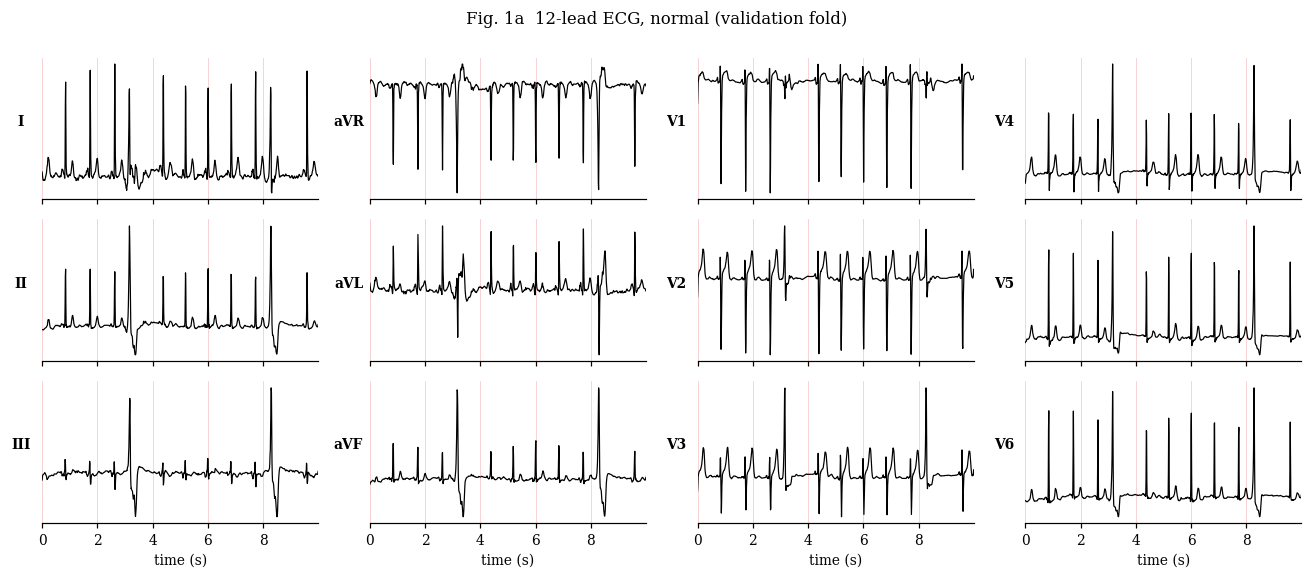

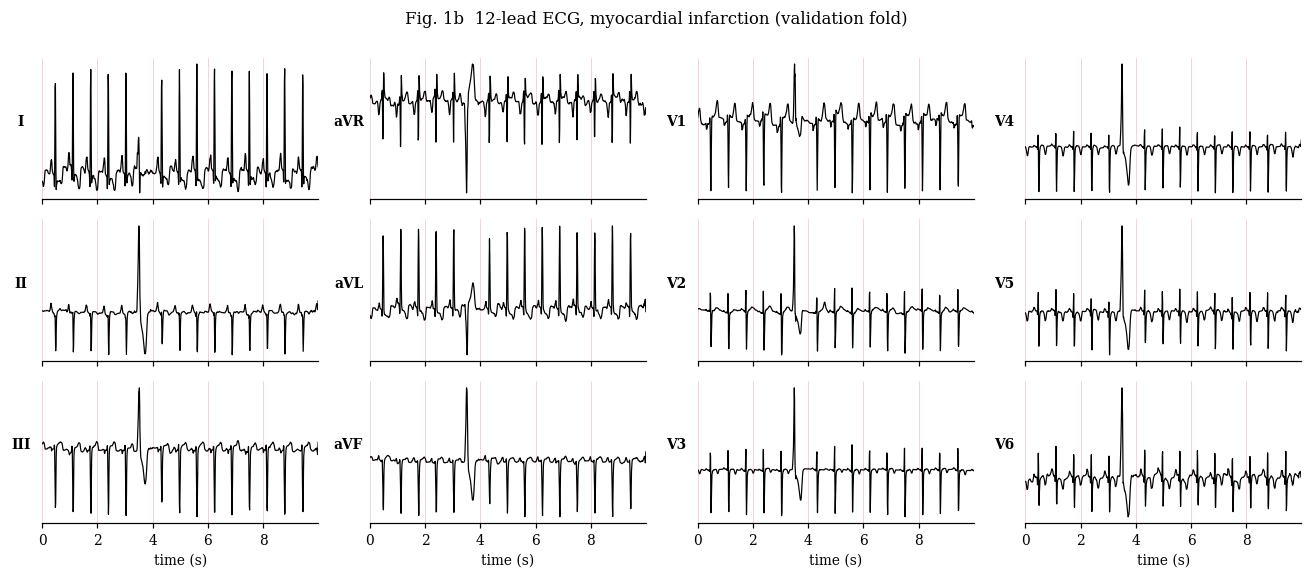

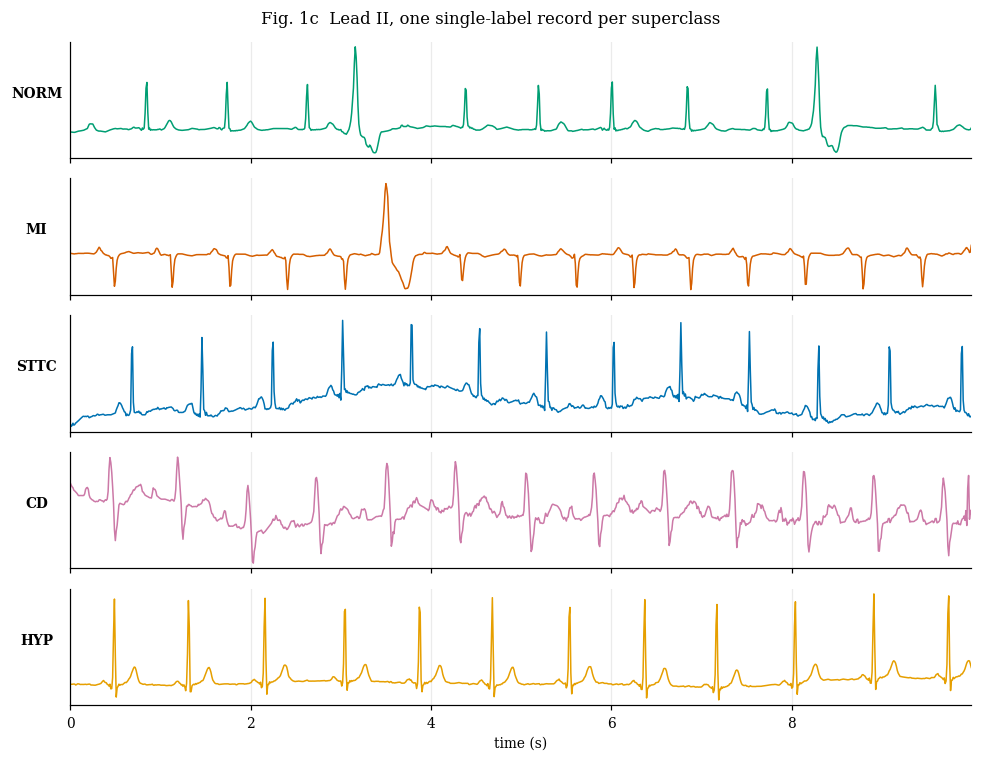

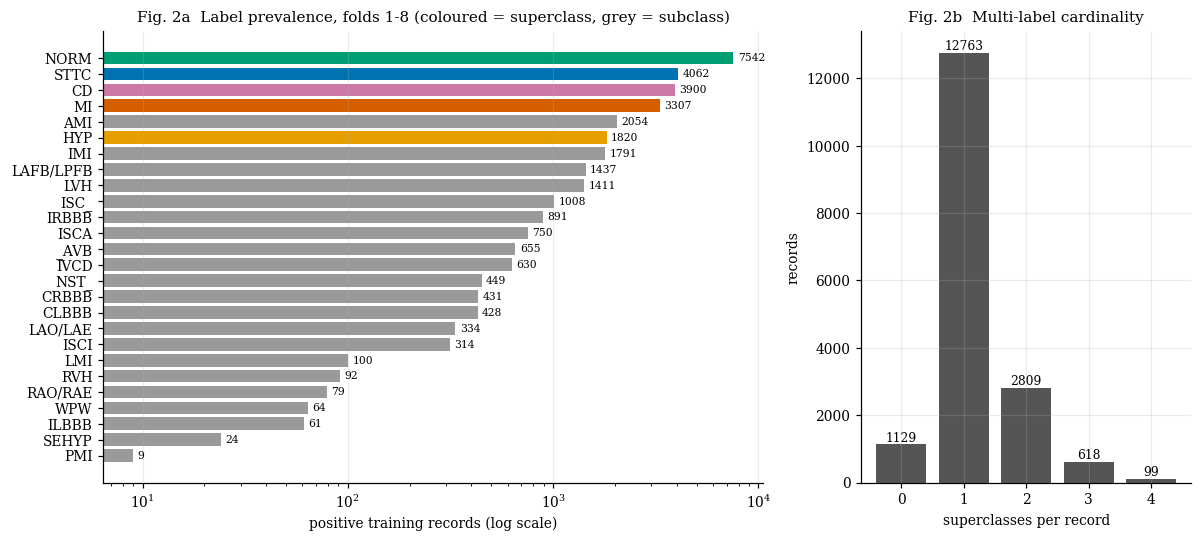

records with 0 superclass labels: 1129 | with >=2: 3526


In [7]:
def denorm(x):                                   # (12,T) standardised -> Stage-1 units
    return x * SD[:, None] + MU[:, None]

Xva_cpu = DATA['X_va'].cpu().numpy()
sup_n = Yva_sup_np.sum(1)
prim = Yva_sup_np.argmax(1)
rng = np.random.default_rng(0)
pure = {c: np.where((sup_n == 1) & (prim == j))[0] for j, c in enumerate(SUPER)}
example = {c: int(rng.choice(pure[c])) for c in SUPER}

def plot_12lead(sig12, title, name):
    grid_idx = [[0, 3, 6, 9], [1, 4, 7, 10], [2, 5, 8, 11]]
    t = np.arange(sig12.shape[1]) / FS
    fig, axes = plt.subplots(3, 4, figsize=(12, 5.2), sharex=True)
    for r in range(3):
        for c in range(4):
            li = grid_idx[r][c]
            ax = axes[r, c]
            ax.plot(t, sig12[li], color='k', lw=0.8)
            ax.grid(True, color='#f2b8b8', lw=0.4, alpha=1)
            ax.set_ylabel(LEADS[li], rotation=0, labelpad=14, fontweight='bold')
            ax.spines['left'].set_visible(False); ax.set_yticks([])
            ax.margins(x=0)
    for ax in axes[-1]: ax.set_xlabel('time (s)')
    fig.suptitle(title, y=1.0)
    fig.tight_layout()
    save_fig(fig, name)

plot_12lead(denorm(Xva_cpu[example['NORM']]), 'Fig. 1a  12-lead ECG, normal (validation fold)', 'fig01a_12lead_norm')
plot_12lead(denorm(Xva_cpu[example['MI']]), 'Fig. 1b  12-lead ECG, myocardial infarction (validation fold)', 'fig01b_12lead_mi')

fig, axes = plt.subplots(5, 1, figsize=(9, 7), sharex=True)
t = np.arange(1000) / FS
for ax, c in zip(axes, SUPER):
    ax.plot(t, denorm(Xva_cpu[example[c]])[1], color=SUPER_COL[c], lw=1.0)
    ax.set_ylabel(c, rotation=0, labelpad=22, fontweight='bold')
    ax.set_yticks([]); ax.margins(x=0)
axes[-1].set_xlabel('time (s)')
fig.suptitle('Fig. 1c  Lead II, one single-label record per superclass')
fig.tight_layout()
save_fig(fig, 'fig01c_leadII_superclasses')

# ---- label statistics (train folds)
counts = Ytr_all_np.sum(0)
order = np.argsort(-counts)
fig, axes = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={'width_ratios': [2, 1]})
ax = axes[0]
cols = [SUPER_COL[ALL_LABELS[i]] if ALL_LABELS[i] in SUPER else '#9a9a9a' for i in order]
ax.barh([ALL_LABELS[i] for i in order][::-1], counts[order][::-1], color=cols[::-1])
ax.set_xscale('log'); ax.set_xlabel('positive training records (log scale)')
for y_, v in enumerate(counts[order][::-1]):
    ax.text(v * 1.05, y_, f'{int(v)}', va='center', fontsize=7)
ax.set_title('Fig. 2a  Label prevalence, folds 1-8 (coloured = superclass, grey = subclass)')
ax.grid(axis='y', alpha=0)
card = Counter(Ytr_sup_np.sum(1).astype(int))
ax = axes[1]
ks = sorted(card)
ax.bar([str(k) for k in ks], [card[k] for k in ks], color='#555555')
for i_, k in enumerate(ks):
    ax.text(i_, card[k], str(card[k]), ha='center', va='bottom', fontsize=8)
ax.set_xlabel('superclasses per record'); ax.set_ylabel('records')
ax.set_title('Fig. 2b  Multi-label cardinality')
fig.tight_layout()
save_fig(fig, 'fig02_label_statistics')
print('records with 0 superclass labels:', card.get(0, 0), '| with >=2:', sum(v for k, v in card.items() if k >= 2))

## 5. Model size and augmentation check
Parameter budget first, then a picture of what the two kinds of views look like. If the augmentations look wrong here, they are wrong in training too.

In [8]:
_m = DEANSSL(CFG).to(dev)
n_enc, n_dec, n_proj = count_params(_m.enc), count_params(_m.dec), count_params(_m.proj)
print(f'encoder (what NB-02 keeps)  : {n_enc/1e6:6.2f} M')
print(f'reconstruction decoder      : {n_dec/1e6:6.2f} M')
print(f'projection head             : {n_proj/1e6:6.2f} M')
print(f'trainable total             : {count_params(_m)/1e6:6.2f} M   (+ frozen EMA copy of encoder/head)')
if not 8e6 <= n_enc <= 16e6:
    print('note: encoder is outside the 8-16 M range planned for DEAN, adjust CFG["depth"] if that matters to you')
del _m
torch.cuda.empty_cache()

encoder (what NB-02 keeps)  :  11.48 M
reconstruction decoder      :   0.14 M
projection head             :   0.10 M
trainable total             :  11.72 M   (+ frozen EMA copy of encoder/head)


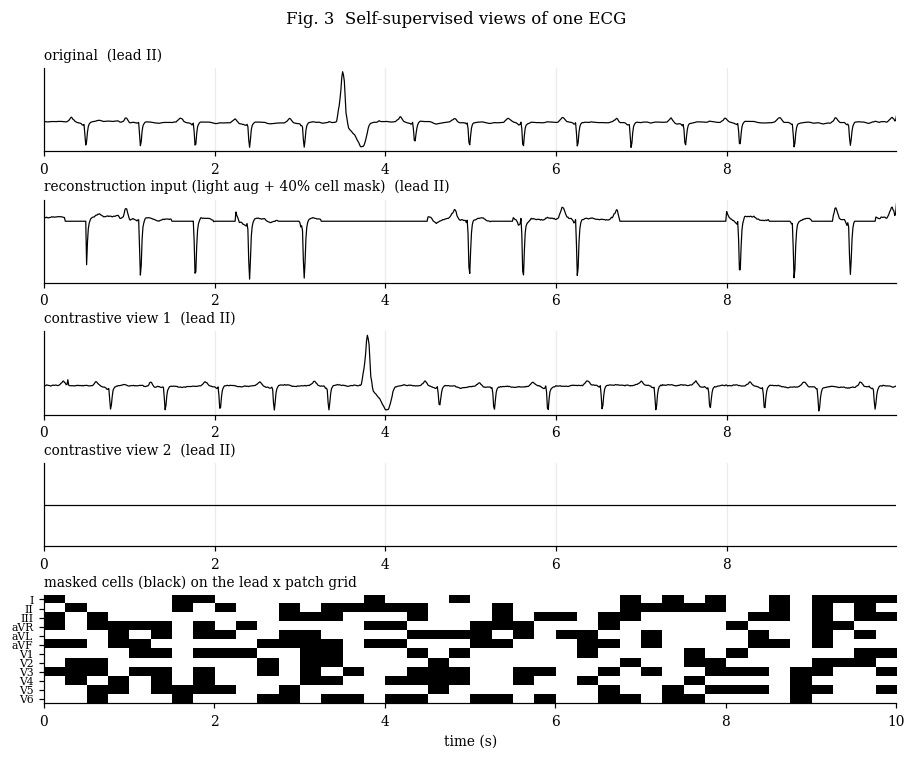

In [9]:
torch.manual_seed(1)
j = example['MI']
x0 = DATA['X_va'][j:j + 1]
x_light = light_aug(x0)
x_masked, grid = random_cell_mask(x_light, CFG['mask_ratio'], CFG['patch'])
v1, v2 = strong_aug(x0), strong_aug(x0)
lead = 1
t = np.arange(1000) / FS
rows = [('original', x0), ('reconstruction input (light aug + 40% cell mask)', x_masked), ('contrastive view 1', v1), ('contrastive view 2', v2)]
fig = plt.figure(figsize=(10, 7.5))
gs = fig.add_gridspec(5, 1, height_ratios=[1, 1, 1, 1, 1.3], hspace=0.55)
for r, (nm, arr) in enumerate(rows):
    ax = fig.add_subplot(gs[r])
    ax.plot(t, arr[0, lead].cpu().numpy(), color='k', lw=0.8)
    ax.set_title(nm + f'  (lead {LEADS[lead]})', fontsize=9, loc='left')
    ax.margins(x=0); ax.set_yticks([])
ax = fig.add_subplot(gs[4])
ax.imshow(grid[0].cpu().numpy(), aspect='auto', cmap='gray_r', extent=[0, 10, 12, 0], interpolation='nearest')
ax.set_yticks(np.arange(12) + 0.5); ax.set_yticklabels(LEADS, fontsize=7)
ax.set_xlabel('time (s)'); ax.set_title('masked cells (black) on the lead x patch grid', fontsize=9, loc='left')
ax.grid(False)
fig.suptitle('Fig. 3  Self-supervised views of one ECG', y=0.95)
save_fig(fig, 'fig03_augmentations')

## 6. Training loop and monitoring
`run_training` is used by both the smoke test and the real run, so what the smoke test proves is the thing that actually runs later.

During training the kNN probe (fold 9, superclass labels, no gradient, nothing learned) is evaluated every `eval_every` epochs. It is the cheapest honest signal that pre-training is learning something clinically relevant rather than just lowering a loss.

In [10]:
def quick_knn(encoder, data, cfg):
    Ztr = embed_all(encoder, data['X_tr'])
    Zva = embed_all(encoder, data['X_va'])
    S = knn_scores(Ztr, data['Ytr_sup'], Zva, k=cfg['knn_k']).cpu().numpy()
    res = auc_per_label(S, data['Yva_sup'], SUPER, min_pos=cfg['knn_min_pos'])
    row = {f'knn_auc_{n}': v for n, v in res.items()}
    row['knn_auc_macro'] = float(np.mean(list(res.values()))) if res else float('nan')
    return row


def find_resume_ckpt():
    local = os.path.join(CKPT_DIR, 'dean_ssl_last.pt')
    if os.path.exists(local):
        return local
    hits = sorted(glob.glob('/kaggle/input/**/dean_ssl_last.pt', recursive=True), key=os.path.getmtime)
    return hits[-1] if hits else None


def run_training(cfg, data, out_dir, resume_path=None, tag='run'):
    os.makedirs(out_dir, exist_ok=True)
    torch.manual_seed(cfg['seed']); np.random.seed(cfg['seed']); random.seed(cfg['seed'])
    model = DEANSSL(cfg).to(dev)
    X = data['X_tr']
    N, bs = X.shape[0], cfg['batch_size']
    spe = N // bs                                   # drop last: queue size must stay divisible
    total, warm = cfg['epochs'] * spe, cfg['warmup_epochs'] * spe

    decay, nodecay = [], []
    for n, p in model.named_parameters():
        if not p.requires_grad or n == 'log_s':
            continue
        (nodecay if (p.ndim < 2 or 'pos_emb' in n) else decay).append(p)
    opt = torch.optim.AdamW([
        {'params': decay, 'weight_decay': cfg['wd'], 'lr_scale': 1.0},
        {'params': nodecay, 'weight_decay': 0.0, 'lr_scale': 1.0},
        {'params': [model.log_s], 'weight_decay': 0.0, 'lr_scale': cfg['lr_s_mult']},
    ], lr=cfg['lr'], betas=(0.9, 0.95))
    scaler = torch.cuda.amp.GradScaler(enabled=cfg['amp'])

    start_epoch, step, history = 0, 0, []
    if resume_path and os.path.exists(resume_path):
        s = torch.load(resume_path, map_location=dev, weights_only=False)
        model.load_state_dict(s['model']); opt.load_state_dict(s['opt']); scaler.load_state_dict(s['scaler'])
        start_epoch, step, history = s['epoch'], s['step'], s['history']
        print(f'[{tag}] resumed from {resume_path}: epoch {start_epoch}, step {step}')
    elif resume_path:
        print(f'[{tag}] resume path given but file missing, starting fresh')

    torch.cuda.reset_peak_memory_stats()
    t_start, bad, stopped_early = time.time(), 0, False
    ckpt_path = os.path.join(out_dir, 'dean_ssl_last.pt')

    for epoch in range(start_epoch, cfg['epochs']):
        model.train()
        t_ep = time.time()
        gen = torch.Generator().manual_seed(cfg['seed'] * 1000 + epoch)    # same shuffling after a resume
        perm = torch.randperm(N, generator=gen).to(dev)
        acc, cnt = defaultdict(float), defaultdict(int)
        bar = tqdm(range(spe), desc=f'[{tag}] epoch {epoch+1}/{cfg["epochs"]}', leave=False)
        for i in bar:
            x = X[perm[i * bs:(i + 1) * bs]]
            lr = lr_at(step, total, warm, cfg['lr'], cfg['min_lr'])
            for g in opt.param_groups:
                g['lr'] = lr * g['lr_scale']
            nce_w = nce_weight(step, total, cfg)
            with torch.autocast('cuda', dtype=torch.float16, enabled=cfg['amp']):
                out = compute_losses(model, x, cfg, nce_w)
            loss = out['loss']
            if not torch.isfinite(loss):
                bad += 1
                opt.zero_grad(set_to_none=True)
                if bad >= 20:
                    raise RuntimeError('20 non-finite losses in a row, stopping. Lower lr or check the data.')
                continue
            bad = 0
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg['clip'])
            scaler.step(opt); scaler.update()
            model.momentum_update(cfg['momentum'])
            if 'k' in out:
                model.enqueue(out['k'])
            step += 1
            for nm in ('loss', 'mse', 'nce', 'pos_sim', 'neg_sim', 'nce_acc', 'emb_std'):
                if nm in out:
                    acc[nm] += float(out[nm]); cnt[nm] += 1
            if i % 20 == 0:
                bar.set_postfix(loss=f'{acc["loss"]/max(1,cnt["loss"]):.3f}', mse=f'{acc["mse"]/max(1,cnt["mse"]):.3f}')
        bar.close()

        done = epoch + 1
        s_now = model.log_s.detach().clamp(-4, 4).cpu()
        ep_time = time.time() - t_ep
        row = {'epoch': done, 'step': step, 'lr': lr, 'nce_weight': nce_w,
               'w_mse': float(torch.exp(-s_now[0])), 'w_nce': float(torch.exp(-s_now[1])),
               's_mse': float(s_now[0]), 's_nce': float(s_now[1]),
               'sec_per_epoch': ep_time, 'sec_per_step': ep_time / spe,
               'gpu_peak_gb': torch.cuda.max_memory_allocated() / 1e9}
        for nm in ('loss', 'mse', 'nce', 'pos_sim', 'neg_sim', 'nce_acc', 'emb_std'):
            row[nm] = acc[nm] / cnt[nm] if cnt[nm] else float('nan')
        if done % cfg['eval_every'] == 0 or done == cfg['epochs']:
            row.update(quick_knn(model.enc, data, cfg))
        history.append(row)

        elapsed_h = (time.time() - t_start) / 3600
        stop_now = bool(cfg['max_hours']) and done < cfg['epochs'] and elapsed_h + 1.5 * ep_time / 3600 > cfg['max_hours']
        if done % cfg['save_every'] == 0 or done == cfg['epochs'] or stop_now:
            save_atomic({'model': model.state_dict(), 'opt': opt.state_dict(), 'scaler': scaler.state_dict(),
                         'epoch': done, 'step': step, 'history': history, 'cfg': cfg}, ckpt_path)
            pd.DataFrame(history).to_csv(os.path.join(out_dir, 'ssl_history_partial.csv'), index=False)
        if cfg['milestone_every'] and done % cfg['milestone_every'] == 0:
            save_atomic({'encoder': model.enc.state_dict(), 'epoch': done},
                        os.path.join(out_dir, f'dean_encoder_ep{done:03d}.pt'))

        knn_txt = f" | kNN-AUC {row['knn_auc_macro']:.4f}" if 'knn_auc_macro' in row else ''
        print(f"[{tag}] ep {done:3d} | loss {row['loss']:.4f} | mse {row['mse']:.4f} | nce {row['nce']:.3f} "
              f"| lr {lr:.2e} | {ep_time:5.0f}s | peak {row['gpu_peak_gb']:.1f} GB{knn_txt}")
        if stop_now:
            stopped_early = True
            print(f'[{tag}] time budget reached after epoch {done}. State saved, re-run the notebook to resume.')
            break

    return dict(model=model, history=history, step=step, steps_per_epoch=spe, stopped_early=stopped_early)

## 7. Smoke test
Runs the real code path on 512 training records for 2 epochs, then resumes from the saved checkpoint for a third. It checks:
1. losses are finite and the reconstruction loss goes through the encoder (gradients exist)
2. the EMA key encoder has no gradients but does follow the online encoder
3. the queue pointer advances
4. checkpoint save, reload and resume give the same weights and continue the step counter
5. peak GPU memory at batch 64, seconds per step, and a projected total training time

If anything fails, fix it here instead of 3 hours into the real run.

In [11]:
def smoke_test(cfg, data):
    print('=' * 70, '\nSMOKE TEST\n' + '=' * 70)
    c = dict(cfg)
    c.update(epochs=2, warmup_epochs=1, eval_every=1, save_every=1, milestone_every=0, max_hours=0,
             nce_start_frac=0.0, nce_ramp_frac=0.25, knn_min_pos=2)
    nsm = 8 * c['batch_size']
    small = dict(X_tr=data['X_tr'][:nsm], X_va=data['X_va'][:300], Ytr_sup=data['Ytr_sup'][:nsm],
                 Yva_sup=data['Yva_sup'][:300], Ytr_all=data['Ytr_all'][:nsm], Yva_all=data['Yva_all'][:300])
    tmp = os.path.join(WORK, 'smoke_tmp')
    shutil.rmtree(tmp, ignore_errors=True)

    # --- 1/2/3: gradient flow, EMA behaviour, queue
    m = DEANSSL(c).to(dev); m.train()
    x = data['X_tr'][:c['batch_size']]
    with torch.autocast('cuda', dtype=torch.float16):
        out = compute_losses(m, x, c, nce_w=1.0)
    assert torch.isfinite(out['loss']), 'loss is not finite'
    out['loss'].backward()
    g_enc = m.enc.patch_embed.weight.grad
    assert g_enc is not None and g_enc.abs().sum() > 0, 'no gradient reaches the encoder'
    assert m.log_s.grad is not None and (m.log_s.grad != 0).all(), 'uncertainty weights get no gradient'
    assert all(p.grad is None for p in m.enc_k.parameters()), 'EMA encoder must not receive gradients'
    before = m.enc_k.patch_embed.weight.detach().clone()
    with torch.no_grad():
        m.enc.patch_embed.weight.add_(0.1)
    m.momentum_update(0.9)
    assert not torch.equal(before, m.enc_k.patch_embed.weight), 'EMA update did nothing'
    p0 = int(m.qptr); m.enqueue(out['k'])
    assert int(m.qptr) == (p0 + c['batch_size']) % c['queue'], 'queue pointer did not advance'
    print('[ok] finite loss, gradient flow, EMA update, queue pointer')
    print(f"     initial  mse {float(out['mse']):.3f} | nce {float(out['nce']):.3f} (chance = ln(Q+1) = {math.log(c['queue']+1):.3f})")
    del m, out; torch.cuda.empty_cache()

    # --- 4: train 2 epochs, save, reload, compare, resume a 3rd epoch
    torch.cuda.reset_peak_memory_stats()
    r1 = run_training(c, small, tmp, tag='smoke')
    ck = os.path.join(tmp, 'dean_ssl_last.pt')
    assert os.path.exists(ck) and len(r1['history']) == 2 and r1['step'] == 16
    saved = torch.load(ck, map_location=dev, weights_only=False)
    m2 = DEANSSL(c).to(dev); m2.load_state_dict(saved['model'])
    for (n1, p1), (n2, p2) in zip(r1['model'].state_dict().items(), m2.state_dict().items()):
        assert n1 == n2 and torch.equal(p1, p2), f'checkpoint round-trip mismatch in {n1}'
    c3 = dict(c); c3['epochs'] = 3
    r2 = run_training(c3, small, tmp, resume_path=ck, tag='smoke-resume')
    assert len(r2['history']) == 3 and r2['step'] == 24, 'resume did not continue the step counter'
    print('[ok] checkpoint round-trip and resume (16 -> 24 steps)')

    # --- 5: memory / speed projection
    peak = torch.cuda.max_memory_allocated() / 1e9
    sps = r2['history'][-1]['sec_per_step']
    spe_full = data['X_tr'].shape[0] // cfg['batch_size']
    est_train_h = sps * spe_full * cfg['epochs'] / 3600
    est_eval_h = (cfg['epochs'] / cfg['eval_every']) * 25 / 3600
    print(f'[ok] peak GPU memory {peak:.1f} GB of {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')
    print(f'     {sps:.2f} s/step at batch {cfg["batch_size"]}  ->  ~{sps*spe_full/60:.1f} min/epoch, '
          f'~{est_train_h + est_eval_h:.1f} h for {cfg["epochs"]} epochs (rough, includes kNN evals)')
    if peak > 14:
        print('     WARNING: close to the VRAM limit, lower batch_size to 32 (and queue stays divisible)')
    if est_train_h > 10:
        print('     note: more than one session needed. The notebook stops itself at max_hours and resumes from the checkpoint.')
    shutil.rmtree(tmp, ignore_errors=True)
    del r1, r2, m2; torch.cuda.empty_cache()
    print('SMOKE TEST PASSED')
    return True


RUN_SMOKE = True      # set False when resuming in a later session
SMOKE_OK = smoke_test(CFG, DATA) if RUN_SMOKE else True

SMOKE TEST
[ok] finite loss, gradient flow, EMA update, queue pointer
     initial  mse 0.944 | nce 3.873 (chance = ln(Q+1) = 8.318)


/tmp/ipykernel_23/1564853632.py:38: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=cfg['amp'])


[smoke] epoch 1/2:   0%|          | 0/8 [00:00<?, ?it/s]

[smoke] ep   1 | loss 4.6481 | mse 0.9931 | nce 5.107 | lr 1.00e-04 |    44s | peak 2.1 GB | kNN-AUC 0.7899


[smoke] epoch 2/2:   0%|          | 0/8 [00:00<?, ?it/s]

[smoke] ep   2 | loss 7.1170 | mse 0.9871 | nce 6.165 | lr 4.77e-06 |    47s | peak 2.3 GB | kNN-AUC 0.7915


/tmp/ipykernel_23/1564853632.py:38: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=cfg['amp'])


[smoke-resume] resumed from /kaggle/working/smoke_tmp/dean_ssl_last.pt: epoch 2, step 16


[smoke-resume] epoch 3/3:   0%|          | 0/8 [00:00<?, ?it/s]

[smoke-resume] ep   3 | loss 7.4830 | mse 0.9694 | nce 6.567 | lr 1.95e-06 |    47s | peak 2.6 GB | kNN-AUC 0.7957
[ok] checkpoint round-trip and resume (16 -> 24 steps)
[ok] peak GPU memory 2.9 GB of 15.6 GB
     5.88 s/step at batch 64  ->  ~26.6 min/epoch, ~11.1 h for 25 epochs (rough, includes kNN evals)
     note: more than one session needed. The notebook stops itself at max_hours and resumes from the checkpoint.
SMOKE TEST PASSED


## 8. Full pre-training
* The cell resumes automatically from `ckpt/dean_ssl_last.pt`, or from a `dean_ssl_last.pt` found in any attached input dataset.
* It stops by itself at `max_hours` after saving. To continue: save a version of the notebook, publish its output as Dataset `dean-ssl-pretrained-v1` (or attach the notebook output), add it as input to a new session, set `RUN_SMOKE = False`, run all.
* Leave `epochs`, `batch_size` and the learning-rate settings untouched between sessions. The cosine schedule is a function of the step counter.

In [12]:
assert SMOKE_OK, 'run the smoke test first'
FORCE_FRESH = False                       # True ignores any checkpoint and starts from scratch
resume = None if FORCE_FRESH else find_resume_ckpt()
print('resuming from:', resume if resume else 'nothing (fresh start)')

result = run_training(CFG, DATA, CKPT_DIR, resume_path=resume, tag='dean-ssl')
print('finished' if not result['stopped_early'] else 'paused (time budget)',
      '| steps', result['step'], '| epochs done', len(result['history']))

resuming from: nothing (fresh start)


/tmp/ipykernel_23/1564853632.py:38: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=cfg['amp'])


[dean-ssl] epoch 1/25:   0%|          | 0/272 [00:00<?, ?it/s]

[dean-ssl] ep   1 | loss 0.9134 | mse 0.9144 | nce nan | lr 5.00e-05 |   779s | peak 2.1 GB


[dean-ssl] epoch 2/25:   0%|          | 0/272 [00:00<?, ?it/s]

[dean-ssl] ep   2 | loss 0.5246 | mse 0.5764 | nce nan | lr 1.00e-04 |   780s | peak 2.1 GB


... (42 outputs left out)

[dean-ssl] epoch 24/25:   0%|          | 0/272 [00:00<?, ?it/s]

[dean-ssl] ep  24 | loss 1.8755 | mse 0.1924 | nce 4.518 | lr 1.46e-06 |  1595s | peak 2.4 GB


[dean-ssl] epoch 25/25:   0%|          | 0/272 [00:00<?, ?it/s]

[dean-ssl] ep  25 | loss 1.8711 | mse 0.1918 | nce 4.514 | lr 1.00e-06 |  1595s | peak 2.4 GB | kNN-AUC 0.8566
finished | steps 6800 | epochs done 25


## 9. Training curves
Everything below reloads from the checkpoint, so it also works in a fresh session that only wants to redo the figures. If training paused early, the figures show the state at the pause.

loaded checkpoint at epoch 25 | step 6800
 epoch     loss      mse      nce  knn_auc_macro
    20 1.900125 0.194980 4.573388       0.855955
    21 1.811971 0.181011 4.555861            NaN
    22 1.852667 0.188074 4.539339            NaN
    23 1.850637 0.188141 4.527585            NaN
    24 1.875500 0.192415 4.517666            NaN
    25 1.871072 0.191815 4.514364       0.856629


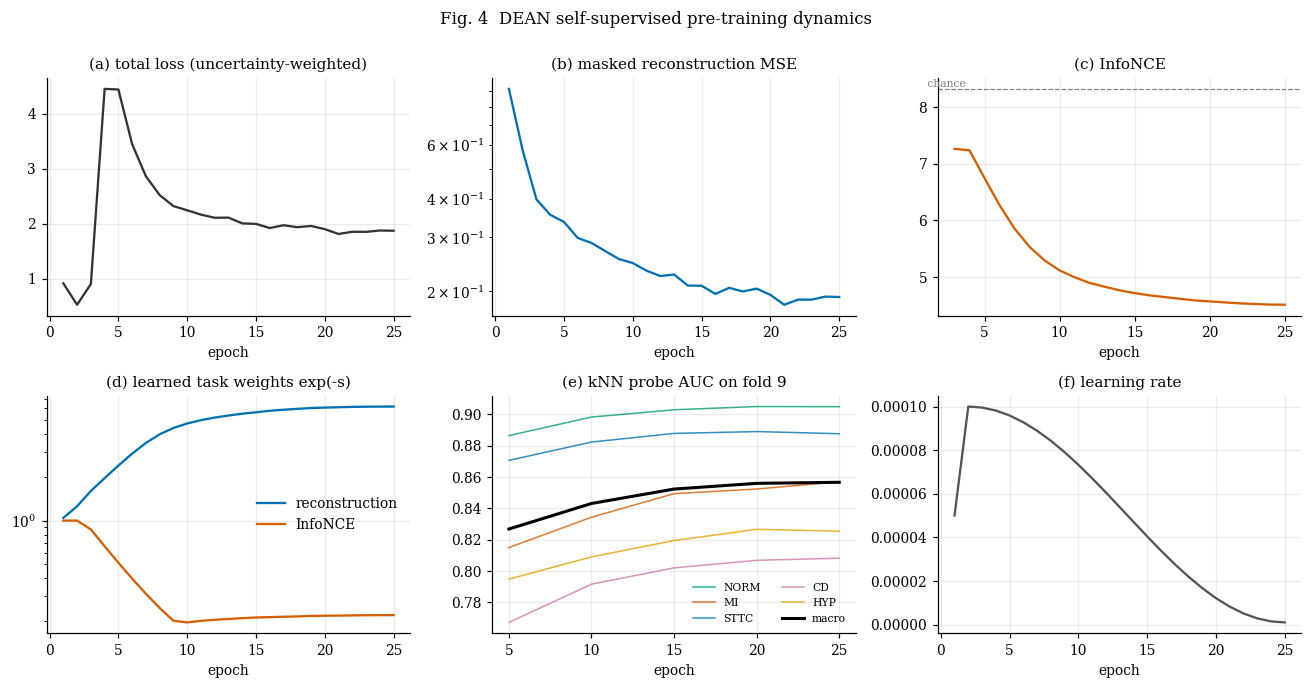

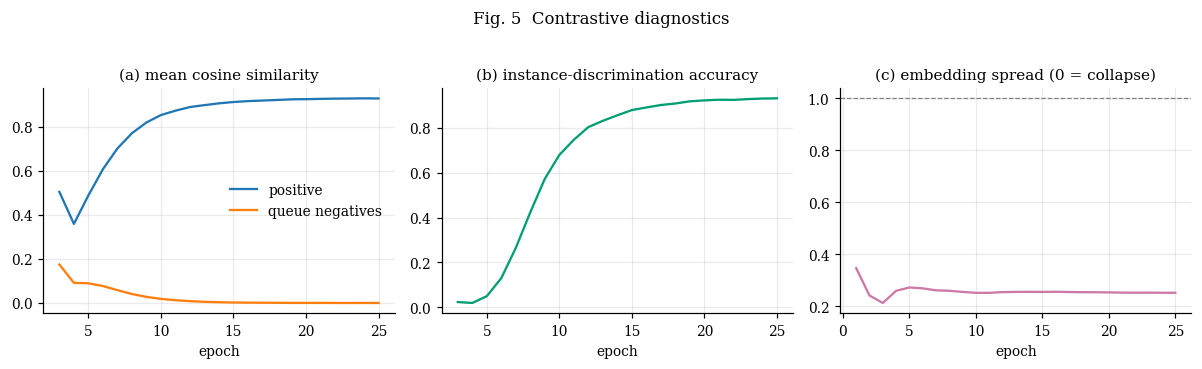

In [13]:
ck = torch.load(os.path.join(CKPT_DIR, 'dean_ssl_last.pt'), map_location=dev, weights_only=False)
CFG_RUN = ck['cfg']
model = DEANSSL(CFG_RUN).to(dev)
model.load_state_dict(ck['model'])
model.eval()
hist = pd.DataFrame(ck['history'])
hist.to_csv(os.path.join(WORK, 'ssl_history.csv'), index=False)
print('loaded checkpoint at epoch', ck['epoch'], '| step', ck['step'])
print(hist[['epoch', 'loss', 'mse', 'nce', 'knn_auc_macro']].tail(6).to_string(index=False))

fig, axes = plt.subplots(2, 3, figsize=(12, 6.2))
ax = axes[0, 0]; ax.plot(hist.epoch, hist.loss, color='#333'); ax.set_title('(a) total loss (uncertainty-weighted)')
ax = axes[0, 1]; ax.plot(hist.epoch, hist.mse, color='#0072B2'); ax.set_yscale('log'); ax.set_title('(b) masked reconstruction MSE')
ax = axes[0, 2]; ax.plot(hist.epoch, hist.nce, color='#D55E00')
ax.axhline(math.log(CFG_RUN['queue'] + 1), ls='--', color='gray', lw=0.8); ax.text(hist.epoch.iloc[0], math.log(CFG_RUN['queue'] + 1), ' chance', va='bottom', fontsize=7, color='gray')
ax.set_title('(c) InfoNCE')
ax = axes[1, 0]; ax.plot(hist.epoch, hist.w_mse, label='reconstruction', color='#0072B2'); ax.plot(hist.epoch, hist.w_nce, label='InfoNCE', color='#D55E00')
ax.set_title('(d) learned task weights exp(-s)'); ax.legend(); ax.set_yscale('log')
ax = axes[1, 1]
kn = hist.dropna(subset=['knn_auc_macro'])
for c_ in SUPER:
    if f'knn_auc_{c_}' in kn: ax.plot(kn.epoch, kn[f'knn_auc_{c_}'], color=SUPER_COL[c_], lw=1, alpha=0.8, label=c_)
ax.plot(kn.epoch, kn.knn_auc_macro, color='k', lw=2, label='macro')
ax.set_title('(e) kNN probe AUC on fold 9'); ax.legend(ncol=2, fontsize=7)
ax = axes[1, 2]; ax.plot(hist.epoch, hist.lr, color='#555'); ax.set_title('(f) learning rate'); ax.set_xlabel('epoch')
for a in axes.ravel(): a.set_xlabel('epoch')
fig.suptitle('Fig. 4  DEAN self-supervised pre-training dynamics', y=1.0)
fig.tight_layout()
save_fig(fig, 'fig04_training_curves')

h2 = hist.dropna(subset=['nce'])
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
axes[0].plot(h2.epoch, h2.pos_sim, label='positive'); axes[0].plot(h2.epoch, h2.neg_sim, label='queue negatives'); axes[0].legend(); axes[0].set_title('(a) mean cosine similarity')
axes[1].plot(h2.epoch, h2.nce_acc, color='#009E73'); axes[1].set_title('(b) instance-discrimination accuracy')
axes[2].plot(hist.epoch, hist.emb_std, color='#CC79A7'); axes[2].axhline(1, ls='--', color='gray', lw=0.8); axes[2].set_title('(c) embedding spread (0 = collapse)')
for a in axes: a.set_xlabel('epoch')
fig.suptitle('Fig. 5  Contrastive diagnostics', y=1.03)
fig.tight_layout()
save_fig(fig, 'fig05_contrastive_diagnostics')

## 10. Reconstruction quality
Fig. 6 shows masked-patch reconstructions. Fig. 7 shows where along the heartbeat and in which leads the model finds reconstruction hard, and how error grows with mask ratio. The zero predictor (= predicting the training mean) is the trivial reference.

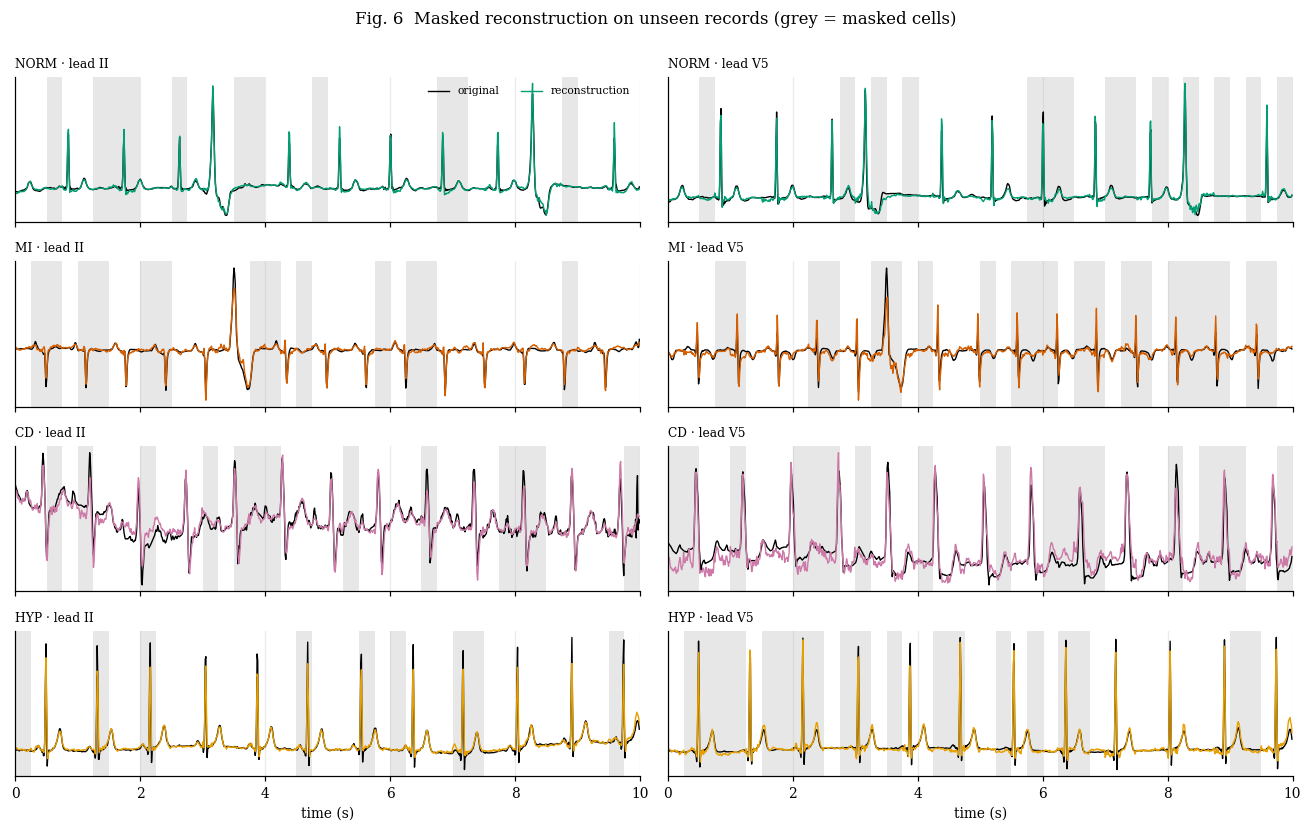

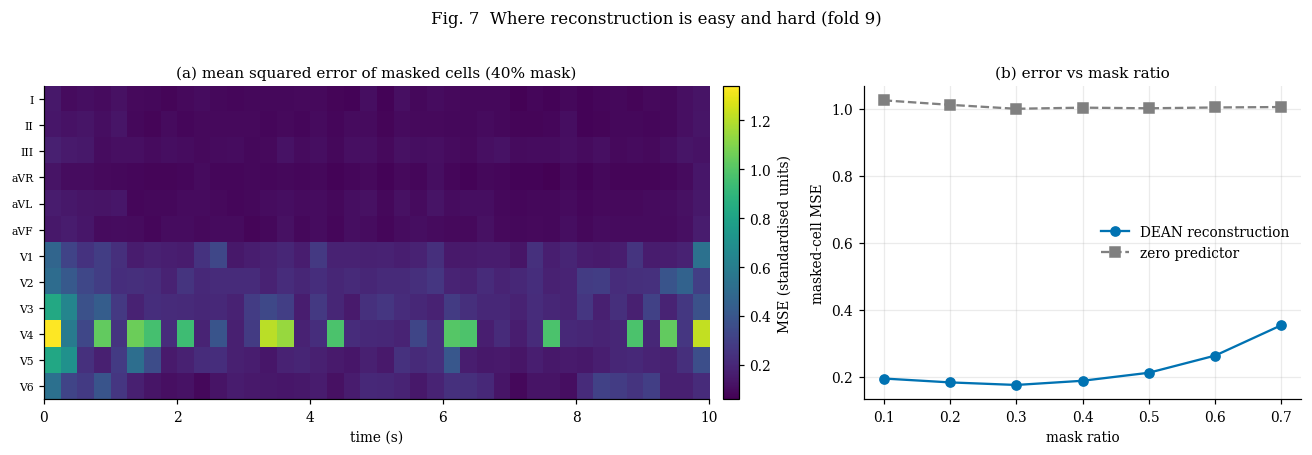

MSE at 40% mask: 0.1882 vs zero predictor 1.0038


In [14]:
Xv = DATA['X_va']
patch = CFG_RUN['patch']

@torch.no_grad()
def reconstruct(x, ratio, seed=0):
    torch.manual_seed(seed)
    x_in, grid = random_cell_mask(x, ratio, patch)
    with torch.autocast('cuda', dtype=torch.float16):
        rec = model.dec(model.enc(x_in)).float()
    return rec, x_in, grid

show = [example[c] for c in ['NORM', 'MI', 'CD', 'HYP']]
xs = Xv[show]
rec, x_in, grid = reconstruct(xs, CFG_RUN['mask_ratio'])
fig, axes = plt.subplots(4, 2, figsize=(12, 7.5), sharex=True)
t = np.arange(1000) / FS
for r, nm in enumerate(['NORM', 'MI', 'CD', 'HYP']):
    for c_, li in enumerate([1, 10]):                     # II and V5
        ax = axes[r, c_]
        ax.plot(t, xs[r, li].cpu(), color='k', lw=0.9, label='original')
        ax.plot(t, rec[r, li].cpu(), color=SUPER_COL[nm], lw=0.9, label='reconstruction')
        for p_ in np.where(grid[r, li].cpu().numpy())[0]:
            ax.axvspan(p_ * patch / FS, (p_ + 1) * patch / FS, color='#bbbbbb', alpha=0.35, lw=0)
        ax.set_yticks([]); ax.margins(x=0)
        ax.set_title(f'{nm} · lead {LEADS[li]}', fontsize=8, loc='left')
axes[0, 0].legend(loc='upper right', fontsize=7, ncol=2)
for ax in axes[-1]: ax.set_xlabel('time (s)')
fig.suptitle('Fig. 6  Masked reconstruction on unseen records (grey = masked cells)', y=1.0)
fig.tight_layout()
save_fig(fig, 'fig06_reconstructions')

@torch.no_grad()
def recon_eval(ratio, bs=256):
    torch.manual_seed(0)
    err = torch.zeros(12, 40, device=dev); cnt = torch.zeros(12, 40, device=dev)
    se = base = n = 0.0
    for i in range(0, len(Xv), bs):
        x = Xv[i:i + bs]
        x_in_, g_ = random_cell_mask(x, ratio, patch)
        with torch.autocast('cuda', dtype=torch.float16):
            r_ = model.dec(model.enc(x_in_)).float()
        e = ((r_ - x) ** 2).view(len(x), 12, 40, patch).mean(-1)
        b0 = (x ** 2).view(len(x), 12, 40, patch).mean(-1)
        err += (e * g_).sum(0); cnt += g_.sum(0)
        se += float((e * g_).sum()); base += float((b0 * g_).sum()); n += float(g_.sum())
    return se / n, base / n, (err / cnt.clamp(min=1)).cpu().numpy()

ratios = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
curve = [recon_eval(r_) for r_ in ratios]
mse_curve = [c_[0] for c_ in curve]; base_curve = [c_[1] for c_ in curve]
err_map = curve[ratios.index(0.4)][2]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={'width_ratios': [1.6, 1]})
im = axes[0].imshow(err_map, aspect='auto', cmap='viridis', extent=[0, 10, 12, 0], interpolation='nearest')
axes[0].set_yticks(np.arange(12) + 0.5); axes[0].set_yticklabels(LEADS, fontsize=7); axes[0].grid(False)
axes[0].set_xlabel('time (s)'); axes[0].set_title('(a) mean squared error of masked cells (40% mask)')
fig.colorbar(im, ax=axes[0], fraction=0.03, pad=0.02, label='MSE (standardised units)')
axes[1].plot(ratios, mse_curve, 'o-', color='#0072B2', label='DEAN reconstruction')
axes[1].plot(ratios, base_curve, 's--', color='gray', label='zero predictor')
axes[1].set_xlabel('mask ratio'); axes[1].set_ylabel('masked-cell MSE'); axes[1].legend(); axes[1].set_title('(b) error vs mask ratio')
fig.suptitle('Fig. 7  Where reconstruction is easy and hard (fold 9)', y=1.02)
fig.tight_layout()
save_fig(fig, 'fig07_reconstruction_error')
print(f'MSE at 40% mask: {mse_curve[3]:.4f} vs zero predictor {base_curve[3]:.4f}')

## 11. Representation quality
All probes here are label-free at training time. Labels of fold 9 are used only to colour plots and score the kNN probe. Comparison against a randomly initialised encoder with the identical architecture shows what pre-training actually bought. The online and the EMA encoder are both evaluated; the better one (by fold-9 kNN macro-AUC) is flagged as `recommended` in the export. That is a mild use of validation data for a binary choice, mention it in the paper.

kNN macro-AUC, 5 superclasses : {'random init': 0.8014, 'DEAN-SSL (online)': 0.8566, 'DEAN-SSL (EMA)': 0.8554}
kNN macro-AUC, subclasses     : {'random init': 0.7326, 'DEAN-SSL (online)': 0.7712, 'DEAN-SSL (EMA)': 0.7691}


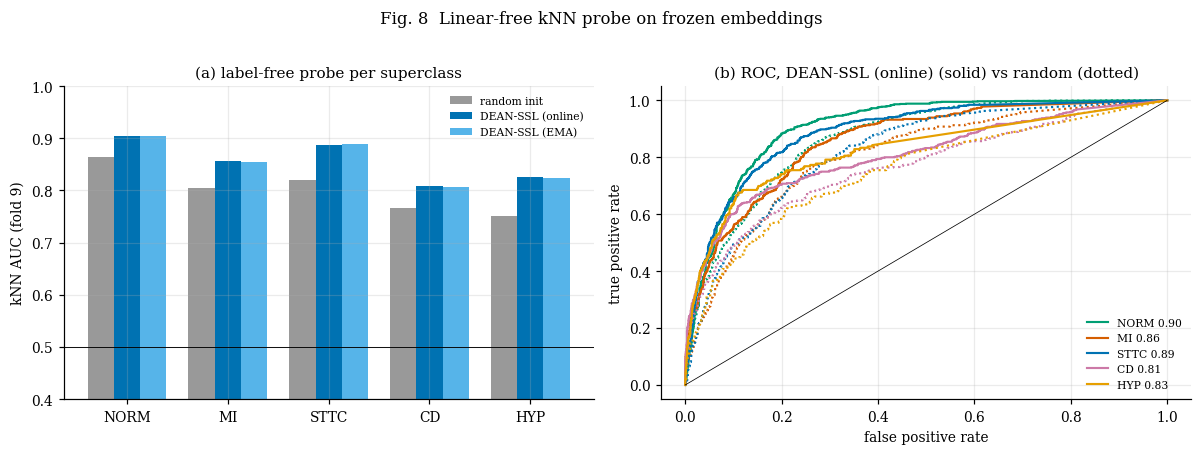

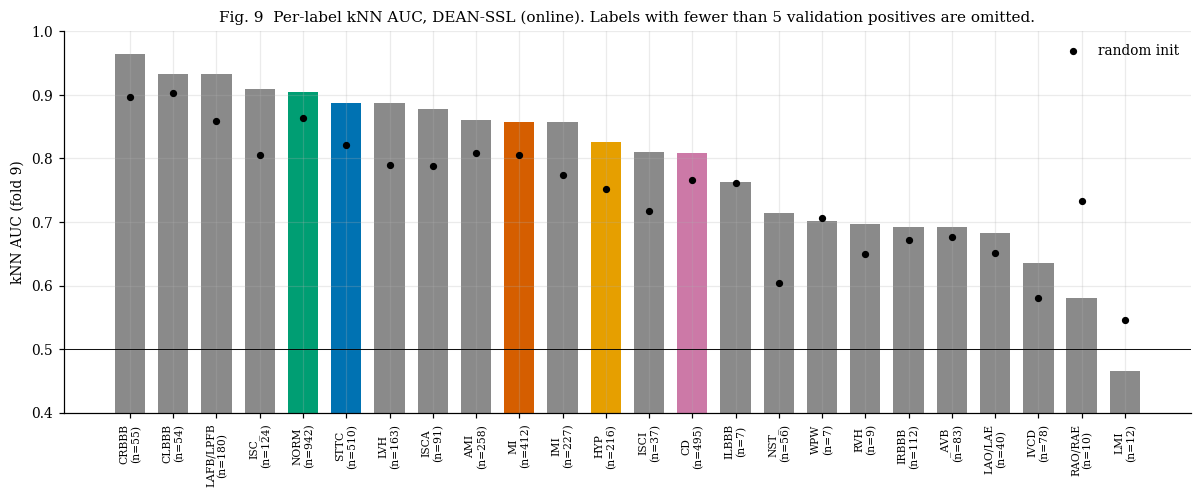

In [15]:
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.metrics import roc_curve

torch.manual_seed(0)
rand_enc = DEANEncoder(**{k: CFG_RUN[k] for k in ENC_KEYS}).to(dev).eval()

enc_sets = {'random init': rand_enc, 'DEAN-SSL (online)': model.enc, 'DEAN-SSL (EMA)': model.enc_k}
Ztr, Zva, S_all = {}, {}, {}
for nm, e in enc_sets.items():
    Ztr[nm] = embed_all(e, DATA['X_tr'])
    Zva[nm] = embed_all(e, DATA['X_va'])
    S_all[nm] = knn_scores(Ztr[nm], DATA['Ytr_all'], Zva[nm], k=CFG_RUN['knn_k']).cpu().numpy()

auc = {nm: auc_per_label(S_all[nm], Yva_all_np, ALL_LABELS, min_pos=5) for nm in enc_sets}
npos = {n: int(Yva_all_np[:, j].sum()) for j, n in enumerate(ALL_LABELS)}
tab = pd.DataFrame({'n_pos_val': pd.Series(npos)})
for nm in enc_sets:
    tab[nm] = pd.Series(auc[nm])
tab = tab.loc[ALL_LABELS]
tab.to_csv(os.path.join(WORK, 'knn_auc_table.csv'))
try:
    tab.round(3).to_latex(os.path.join(WORK, 'knn_auc_table.tex'), na_rep='--')
except Exception as e:
    print('latex export skipped:', e)

macro = {nm: float(np.mean([auc[nm][s] for s in SUPER if s in auc[nm]])) for nm in enc_sets}
macro_sub = {nm: float(np.mean([v for k, v in auc[nm].items() if k not in SUPER])) for nm in enc_sets}
print('kNN macro-AUC, 5 superclasses :', {k: round(v, 4) for k, v in macro.items()})
print('kNN macro-AUC, subclasses     :', {k: round(v, 4) for k, v in macro_sub.items()})

# ---- Fig 8: bars + ROC
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
w = 0.26; xs_ = np.arange(5)
for i, (nm, colr) in enumerate(zip(enc_sets, ['#999999', '#0072B2', '#56B4E9'])):
    axes[0].bar(xs_ + (i - 1) * w, [auc[nm].get(s, np.nan) for s in SUPER], w, label=nm, color=colr)
axes[0].set_xticks(xs_); axes[0].set_xticklabels(SUPER); axes[0].set_ylim(0.4, 1.0)
axes[0].axhline(0.5, color='k', lw=0.6); axes[0].set_ylabel('kNN AUC (fold 9)'); axes[0].legend(fontsize=7)
axes[0].set_title('(a) label-free probe per superclass')
best_nm = 'DEAN-SSL (EMA)' if macro['DEAN-SSL (EMA)'] > macro['DEAN-SSL (online)'] else 'DEAN-SSL (online)'
for j, s in enumerate(SUPER):
    for nm, ls in [(best_nm, '-'), ('random init', ':')]:
        fpr, tpr, _ = roc_curve(Yva_all_np[:, j], S_all[nm][:, j])
        axes[1].plot(fpr, tpr, ls=ls, color=SUPER_COL[s], lw=1.4,
                     label=f'{s} {auc[nm].get(s, float("nan")):.2f}' if ls == '-' else None)
axes[1].plot([0, 1], [0, 1], color='k', lw=0.5)
axes[1].set_xlabel('false positive rate'); axes[1].set_ylabel('true positive rate'); axes[1].legend(fontsize=7)
axes[1].set_title(f'(b) ROC, {best_nm} (solid) vs random (dotted)')
fig.suptitle('Fig. 8  Linear-free kNN probe on frozen embeddings', y=1.02)
fig.tight_layout()
save_fig(fig, 'fig08_knn_probe')

# ---- Fig 9: 26-label AUC
fig, ax = plt.subplots(figsize=(11, 4.6))
sel = [l for l in ALL_LABELS if l in auc[best_nm]]
sel = sorted(sel, key=lambda l: -auc[best_nm][l])
xs_ = np.arange(len(sel))
ax.bar(xs_, [auc[best_nm][l] for l in sel], color=[SUPER_COL.get(l, '#8a8a8a') for l in sel], width=0.7)
ax.scatter(xs_, [auc['random init'].get(l, np.nan) for l in sel], color='k', s=14, zorder=3, label='random init')
ax.set_xticks(xs_); ax.set_xticklabels([f'{l}\n(n={npos[l]})' for l in sel], rotation=90, fontsize=7)
ax.set_ylim(0.4, 1.0); ax.axhline(0.5, color='k', lw=0.6); ax.set_ylabel('kNN AUC (fold 9)'); ax.legend()
ax.set_title(f'Fig. 9  Per-label kNN AUC, {best_nm}. Labels with fewer than 5 validation positives are omitted.')
fig.tight_layout()
save_fig(fig, 'fig09_per_label_auc')

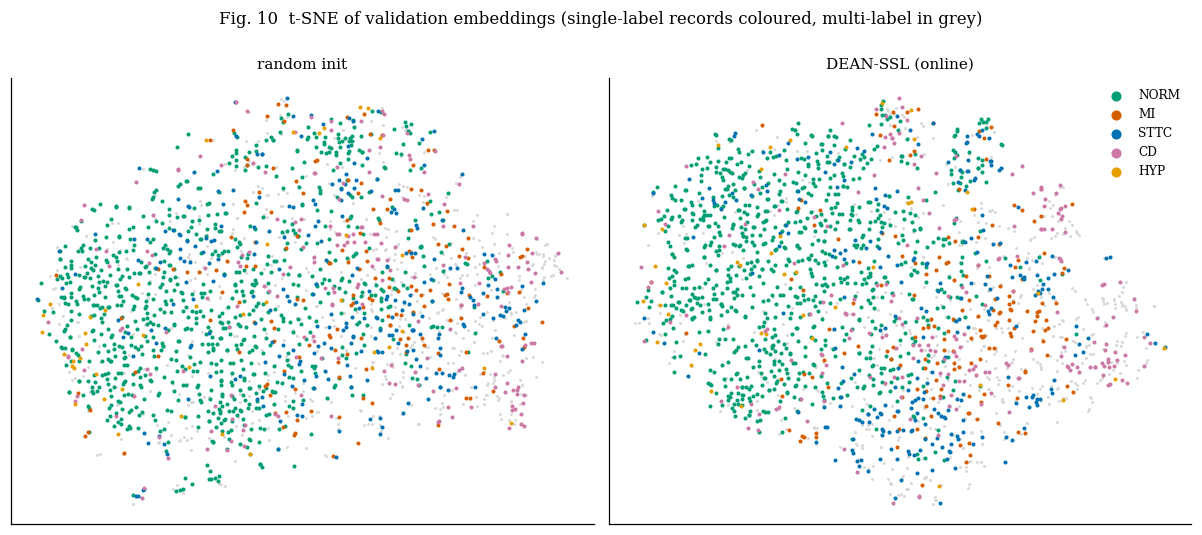

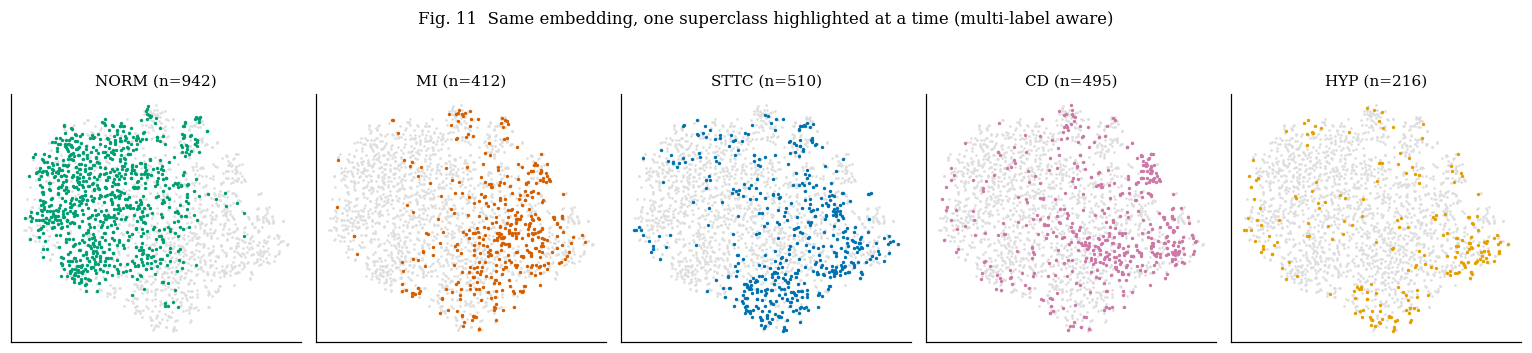

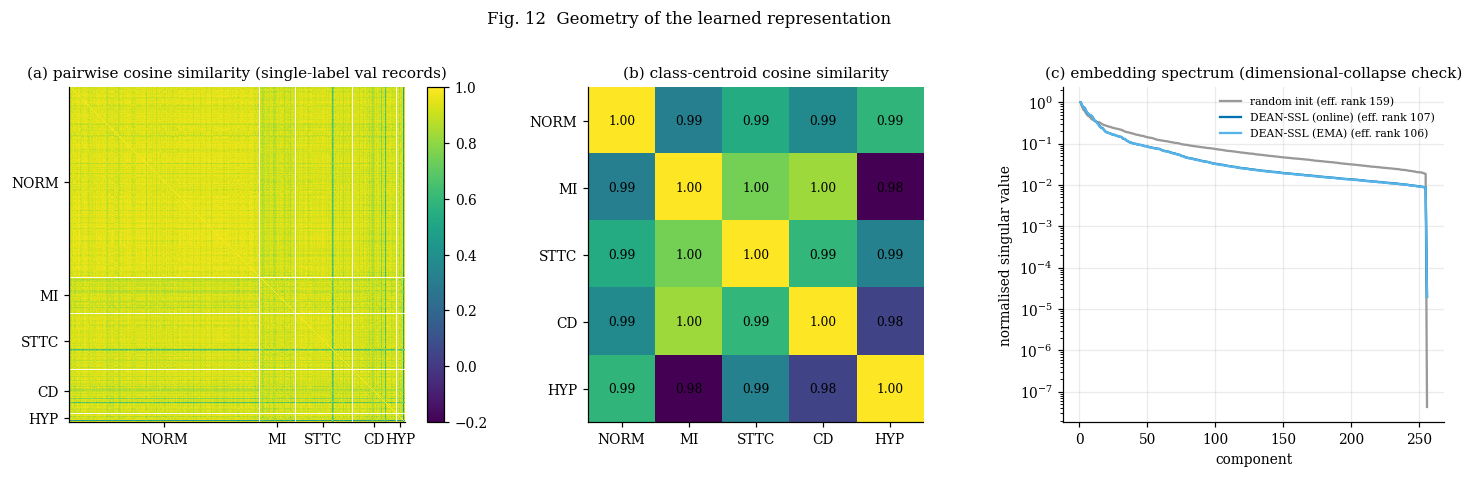

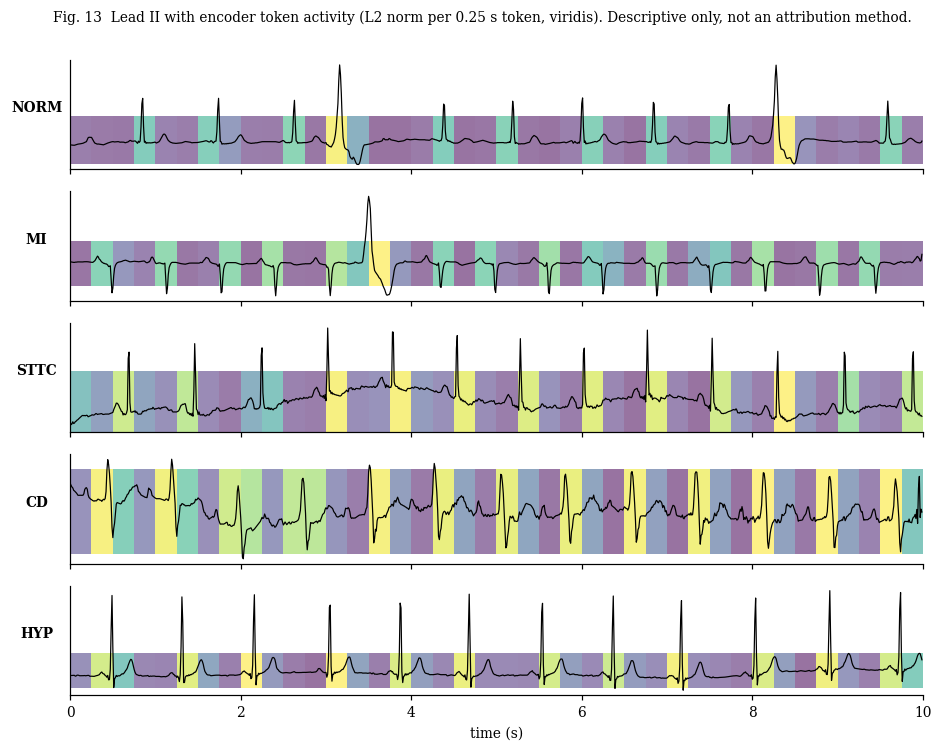

In [16]:
# ---- Fig 10: t-SNE random vs SSL
single = np.where(sup_n == 1)[0]
def tsne_xy(Z):
    Zn = F.normalize(Z, dim=1).cpu().numpy()
    Zp = PCA(n_components=50, random_state=0).fit_transform(Zn)
    return TSNE(n_components=2, perplexity=30, init='pca', learning_rate='auto', random_state=0).fit_transform(Zp)

XY = {nm: tsne_xy(Zva[nm]) for nm in ['random init', best_nm]}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, nm in zip(axes, ['random init', best_nm]):
    xy = XY[nm]
    ax.scatter(xy[:, 0], xy[:, 1], s=4, c='#d9d9d9', lw=0)
    for j, s in enumerate(SUPER):
        ii = single[prim[single] == j]
        ax.scatter(xy[ii, 0], xy[ii, 1], s=7, color=SUPER_COL[s], lw=0, label=s)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(nm); ax.grid(False)
axes[1].legend(markerscale=2.5, fontsize=8, loc='best')
fig.suptitle('Fig. 10  t-SNE of validation embeddings (single-label records coloured, multi-label in grey)', y=1.0)
fig.tight_layout()
save_fig(fig, 'fig10_tsne_random_vs_ssl')

# ---- Fig 11: one-vs-rest small multiples
xy = XY[best_nm]
fig, axes = plt.subplots(1, 5, figsize=(14, 3))
for j, (ax, s) in enumerate(zip(axes, SUPER)):
    pos = Yva_sup_np[:, j] == 1
    ax.scatter(xy[~pos, 0], xy[~pos, 1], s=3, c='#dddddd', lw=0)
    ax.scatter(xy[pos, 0], xy[pos, 1], s=5, color=SUPER_COL[s], lw=0)
    ax.set_title(f'{s} (n={int(pos.sum())})'); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle('Fig. 11  Same embedding, one superclass highlighted at a time (multi-label aware)', y=1.05)
fig.tight_layout()
save_fig(fig, 'fig11_tsne_one_vs_rest')

# ---- Fig 12: similarity structure + spectrum
Zn = F.normalize(Zva[best_nm], dim=1)
o = single[np.argsort(prim[single], kind='stable')]
Sm = (Zn[o] @ Zn[o].t()).cpu().numpy()
bounds = np.cumsum([np.sum(prim[single] == j) for j in range(5)])
cent = torch.stack([F.normalize(Zn[single[prim[single] == j]].mean(0), dim=0) for j in range(5)])
Cm = (cent @ cent.t()).cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), gridspec_kw={'width_ratios': [1.2, 1, 1]})
im = axes[0].imshow(Sm, cmap='viridis', vmin=-0.2, vmax=1.0, interpolation='nearest'); axes[0].grid(False)
for b in bounds[:-1]:
    axes[0].axhline(b - 0.5, color='w', lw=0.6); axes[0].axvline(b - 0.5, color='w', lw=0.6)
mid = np.concatenate([[0], bounds])[:-1] + np.diff(np.concatenate([[0], bounds])) / 2
axes[0].set_xticks(mid); axes[0].set_xticklabels(SUPER); axes[0].set_yticks(mid); axes[0].set_yticklabels(SUPER)
fig.colorbar(im, ax=axes[0], fraction=0.045); axes[0].set_title('(a) pairwise cosine similarity (single-label val records)')
im2 = axes[1].imshow(Cm, cmap='viridis', vmin=Cm.min(), vmax=1.0); axes[1].grid(False)
for a_ in range(5):
    for b_ in range(5):
        axes[1].text(b_, a_, f'{Cm[a_, b_]:.2f}', ha='center', va='center', color='w' if Cm[a_, b_] < 0.9 * Cm.max() else 'k', fontsize=8)
axes[1].set_xticks(range(5)); axes[1].set_xticklabels(SUPER); axes[1].set_yticks(range(5)); axes[1].set_yticklabels(SUPER)
axes[1].set_title('(b) class-centroid cosine similarity')
eff_rank = {}
for nm, colr in zip(enc_sets, ['#999999', '#0072B2', '#56B4E9']):
    Zc = F.normalize(Zva[nm], dim=1); Zc = Zc - Zc.mean(0, keepdim=True)
    sv = torch.linalg.svdvals(Zc.float()).cpu().numpy()
    p_ = sv / sv.sum(); eff_rank[nm] = float(np.exp(-(p_ * np.log(p_ + 1e-12)).sum()))
    axes[2].plot(np.arange(1, len(sv) + 1), sv / sv[0], color=colr, label=f'{nm} (eff. rank {eff_rank[nm]:.0f})')
axes[2].set_yscale('log'); axes[2].set_xlabel('component'); axes[2].set_ylabel('normalised singular value'); axes[2].legend(fontsize=7)
axes[2].set_title('(c) embedding spectrum (dimensional-collapse check)')
fig.suptitle('Fig. 12  Geometry of the learned representation', y=1.02)
fig.tight_layout()
save_fig(fig, 'fig12_embedding_geometry')

# ---- Fig 13: token activity along the heartbeat
fig, axes = plt.subplots(5, 1, figsize=(10, 7.5), sharex=True)
t = np.arange(1000) / FS
with torch.no_grad():
    for ax, s in zip(axes, SUPER):
        xx = Xv[example[s]:example[s] + 1]
        tok_norm = model.enc(xx)[0].float().norm(dim=-1).cpu().numpy()
        tok_norm = (tok_norm - tok_norm.min()) / (np.ptp(tok_norm) + 1e-9)
        ax.imshow(tok_norm[None, :], aspect='auto', cmap='viridis', extent=[0, 10, -3, 3], alpha=0.55, interpolation='nearest')
        ax.plot(t, xx[0, 1].cpu(), color='k', lw=0.8)
        ax.set_ylabel(s, rotation=0, labelpad=22, fontweight='bold'); ax.set_yticks([]); ax.grid(False)
axes[-1].set_xlabel('time (s)')
fig.suptitle('Fig. 13  Lead II with encoder token activity (L2 norm per 0.25 s token, viridis). Descriptive only, not an attribution method.', y=0.94, fontsize=9)
save_fig(fig, 'fig13_token_activity')

## 12. Export for NB-02
Writes the encoder weights (online and EMA), architecture config and normalisation statistics. NB-02 must apply the same per-lead standardisation (`norm_mean`, `norm_std`) to its inputs.

In [17]:
recommended = 'encoder_ema' if best_nm.endswith('(EMA)') else 'encoder'
enc_cfg = {k: CFG_RUN[k] for k in ENC_KEYS}

torch.save({
    'encoder': model.enc.state_dict(), 'encoder_ema': model.enc_k.state_dict(),
    'recommended': recommended, 'enc_config': enc_cfg,
    'norm_mean': MU.tolist(), 'norm_std': SD.tolist(),
    'epochs_done': int(ck['epoch']), 'knn_macro_auc_super': macro,
}, os.path.join(WORK, 'dean_encoder_ssl.pt'))

cfg_json = {
    'enc_config': enc_cfg, 'ssl_config': {k: v for k, v in CFG_RUN.items() if k != 'device'},
    'sampling_rate': FS, 'leads': LEADS, 'super_labels': SUPER, 'sub_labels': SUB, 'label_columns': ALL_LABELS,
    'norm_mean': MU.tolist(), 'norm_std': SD.tolist(), 'recommended_encoder_key': recommended,
    'train_folds': [1, 2, 3, 4, 5, 6, 7, 8], 'monitor_fold': 9,
    'embedding_dim': CFG_RUN['d_model'], 'n_tokens': CFG_RUN['seq_len'] // CFG_RUN['patch'],
}
json.dump(cfg_json, open(os.path.join(WORK, 'dean_config.json'), 'w'), indent=2)

metrics = {
    'epochs_done': int(ck['epoch']), 'total_steps': int(ck['step']),
    'encoder_params_M': count_params(model.enc) / 1e6,
    'final_train_loss': float(hist.loss.iloc[-1]), 'final_masked_mse': float(hist.mse.iloc[-1]),
    'masked_mse_at_40pct': mse_curve[3], 'zero_predictor_mse_at_40pct': base_curve[3],
    'knn_macro_auc_super': macro, 'knn_macro_auc_sub': macro_sub, 'effective_rank': eff_rank,
    'recommended_encoder': recommended,
    'train_hours_last_session': float(hist.sec_per_epoch.tail(max(1, len(hist))).sum() / 3600),
}
json.dump(metrics, open(os.path.join(WORK, 'ssl_metrics.json'), 'w'), indent=2)
np.save(os.path.join(WORK, 'val_embeddings_ssl.npy'), Zva[best_nm].cpu().numpy())

shutil.rmtree(os.path.join(WORK, 'smoke_tmp'), ignore_errors=True)
print(json.dumps({k: metrics[k] for k in ['epochs_done', 'encoder_params_M', 'knn_macro_auc_super', 'recommended_encoder']}, indent=1))
print('\nfiles in /kaggle/working:')
for root, _, files in os.walk(WORK):
    for f in sorted(files):
        p = os.path.join(root, f)
        if '/.' in p or p.endswith('.tmp'):
            continue
        print(f'  {os.path.relpath(p, WORK):45s} {os.path.getsize(p)/1e6:8.2f} MB')

{
 "epochs_done": 25,
 "encoder_params_M": 11.482368,
 "knn_macro_auc_super": {
  "random init": 0.8013947640905773,
  "DEAN-SSL (online)": 0.8566293825289073,
  "DEAN-SSL (EMA)": 0.8553611643737984
 },
 "recommended_encoder": "encoder"
}

files in /kaggle/working:
  __notebook__.ipynb                                2.64 MB
  dean_config.json                                  0.00 MB
  dean_encoder_ssl.pt                              92.05 MB
  dean_lib.py                                       0.01 MB
  knn_auc_table.csv                                 0.00 MB
  knn_auc_table.tex                                 0.00 MB
  ssl_history.csv                                   0.01 MB
  ssl_metrics.json                                  0.00 MB
  val_embeddings_ssl.npy                            2.24 MB
  __pycache__/dean_lib.cpython-313.pyc              0.03 MB
  figures/fig01a_12lead_norm.pdf                    0.07 MB
  figures/fig01a_12lead_norm.png                    0.42 MB
  figures/fig0

## 13. After this notebook
1. Save a version of the notebook, then create Dataset **`dean-ssl-pretrained-v1`** from the output (`dean_encoder_ssl.pt`, `dean_config.json`, `dean_lib.py`, `ckpt/`, `figures/` are the important parts).
2. NB-02 attaches both `ptbxl-processed-v1` and `dean-ssl-pretrained-v1`, does `sys.path.append(<dataset dir>)`, `import dean_lib`, builds `DEANEncoder(**cfg['enc_config'])` and loads the weights under the key named in `recommended`. Input scaling must use `norm_mean` / `norm_std` from the same file.
3. Numbers to carry forward: embedding dimension is **256**, token count **40**, 26 label columns (5 + 21). The gating network input is therefore 256-d.
4. For the paper: the headline pre-training claims are (i) masked-cell MSE vs the zero predictor, (ii) kNN macro-AUC of the SSL encoder vs the random-init encoder at identical architecture, (iii) the embedding spectrum showing no dimensional collapse. All three are in `ssl_metrics.json`.